# Facial Emotion Recognition Research — Reproducible Multi-Dataset Experiments

This notebook builds on the *Comparative Report on Facial Emotion Recognition Models*. It does **not**
assume that any change helps: every proposed improvement is switched on and off under one fixed
protocol, judged on the **validation** set only, and the **test set is opened once**, after the final
model has been chosen and that choice has been written to disk (a code guard enforces this).

**How to run**
1. Keep `config.yaml` next to this notebook (or set `FER_CONFIG_DIR` to its folder).
2. Edit the `datasets` section to point to compatible local data. Relative paths are resolved from `config.yaml`.
3. Pick `training.profile` (`smoke`, `quick`, or `full`) in `config.yaml`.
4. Run all cells. Finished training runs are cached in `OUTPUT_DIR`, so a disconnected Colab session can
   simply be re-run and will continue where it stopped.

The provided configuration enables the FER2013 CSV with official splits and RAVDESS videos. Image-folder
FER2013 is available as an alternative; CK+ and CREMA-D are disabled because the current CK+ folder contains
only a CSV and CREMA-D contains audio-only files.

Expected project layout:
```text
Facial Emotion Research/
  facial_emotion_research.ipynb
  config.yaml
  outputs/                 # created by the notebook; experiment artifacts are kept here
```

**Google Colab:** upload this notebook, put `config.yaml` and the datasets in Google Drive, then run
```python
from google.colab import drive; drive.mount("/content/drive")
import os; os.environ["FER_CONFIG_DIR"] = "/content/drive/MyDrive/FER"   # folder that contains config.yaml
```
and choose *Runtime → Change runtime type → GPU*. Set `OUTPUT_DIR` in `config.yaml` to a Drive folder.

**Requirements:** Python ≥ 3.10, PyTorch ≥ 2.1, timm, PyYAML, OpenCV, scikit-learn, pandas, seaborn (missing ones are
installed automatically); `onnx`, `onnxscript` and `onnxruntime` are optional, for the ONNX export check.

No accuracy figure in this notebook is written by hand: every number in the result tables is computed
by the cells that produce it.

## 0. Study design and evidence rules

This project trains image-based emotion classifiers and optionally extracts face crops from video.
Every reported score is generated from an executed run; this notebook ships with no claimed new results.
Validation data select models and settings. The held-out test partition is evaluated only after selection is locked.

The experiment stages cover baseline reproduction, controlled recipe ablations, scratch-versus-transfer
training, architecture search, optional FER+ labels, multiple seeds, validation-selected ensembling,
cross-dataset evaluation, robustness checks, and export/CPU efficiency measurements. Dataset and stage
availability is checked at runtime; unsupported or disabled sources are reported rather than imputed.

The YAML file is the project interface. It declares dataset paths and enables, split protocol, model profiles,
training recipe, evaluation, checkpoint, deployment and logging settings. Keep the YAML snapshot with each run.

## 1. Environment, configuration and reproducibility
Installs `timm` if it is missing, loads `config.yaml`, checks every configured path, selects the device and
writes a run manifest (package versions, GPU, resolved settings) so results can be traced later.

In [1]:
import os, sys, json, time, math, hashlib, random, re, platform, warnings, copy, importlib, subprocess
from pathlib import Path
from types import SimpleNamespace
from dataclasses import dataclass, asdict, replace, field

def _ensure(pkg, pip_name=None):
    try:
        return importlib.import_module(pkg)
    except ImportError:
        print(f"Installing missing package: {pip_name or pkg}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg])
        return importlib.import_module(pkg)

np = _ensure("numpy")
pd = _ensure("pandas")
_ensure("matplotlib"); _ensure("seaborn"); _ensure("sklearn", "scikit-learn"); _ensure("scipy")
_ensure("cv2", "opencv-python-headless")
yaml = _ensure("yaml", "pyyaml")
torch = _ensure("torch")
timm = _ensure("timm")
import cv2
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from scipy import stats
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix)
from sklearn.model_selection import train_test_split, GroupShuffleSplit
try:
    from IPython.display import display, Markdown
except ImportError:  # running as a plain script
    display = print
    Markdown = str

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", context="notebook")
CODE_VERSION = "1.0"

# ---------------------------------------------------------------- configuration
_NOTEBOOK_FILE = globals().get("__vsc_ipynb_file__")
_DEFAULT_CONFIG_DIR = Path(_NOTEBOOK_FILE).expanduser().resolve().parent if _NOTEBOOK_FILE else Path.cwd()
CONFIG_DIR = Path(os.environ.get("FER_CONFIG_DIR", _DEFAULT_CONFIG_DIR)).expanduser().resolve()
CONFIG_PATH = CONFIG_DIR / "config.yaml"
if not CONFIG_PATH.is_file():
    raise FileNotFoundError(
        f"config.yaml not found in {CONFIG_DIR}.\n"
        "Put config.yaml in the same folder as this notebook, or set the environment variable "
        "FER_CONFIG_DIR to the folder that contains it (on Colab: upload it to /content or to Drive).")
with CONFIG_PATH.open("r", encoding="utf-8") as config_file:
    CONFIG = yaml.safe_load(config_file)
if not isinstance(CONFIG, dict):
    raise ValueError(f"{CONFIG_PATH} must contain a YAML mapping at the top level.")
REQUIRED_SECTIONS = {
    "project", "datasets", "label_mapping", "splits", "data_validation", "preprocessing",
    "face_extraction", "models", "initialization", "augmentation", "loss", "optimizer",
    "scheduler", "training", "hyperparameter_search", "experiments", "evaluation", "ensemble",
    "checkpointing", "deployment", "logging",
}
missing_sections = REQUIRED_SECTIONS - CONFIG.keys()
if missing_sections:
    raise ValueError(f"config.yaml is missing required sections: {sorted(missing_sections)}")
EXPECTED_CLASSES = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
if CONFIG["label_mapping"].get("class_names") != EXPECTED_CLASSES:
    raise ValueError(f"label_mapping.class_names must match the notebook class order: {EXPECTED_CLASSES}")
if CONFIG["scheduler"].get("name") not in {"cosine", "constant"}:
    raise ValueError("scheduler.name currently supports only 'cosine' or 'constant'.")
if CONFIG["optimizer"].get("name") not in {"adamw", "adam", "sgd"}:
    raise ValueError("optimizer.name must be one of: adamw, adam, sgd.")
if CONFIG["models"].get("num_classes") != len(CONFIG["label_mapping"]["class_names"]):
    raise ValueError("models.num_classes must equal the number of configured label_mapping.class_names.")
D = CONFIG["datasets"]
def _dataset_path(name, field):
    dataset = D.get(name, {})
    return dataset.get(field) if dataset.get("enabled", False) else None

PATHS_CONFIG = {
    "FER2013_CSV": _dataset_path("fer2013", "csv_path"),
    "FER2013_DIR": _dataset_path("fer2013", "image_dir"),
    "FERPLUS_CSV": _dataset_path("ferplus", "csv_path"),
    "CKPLUS_DIR": _dataset_path("ckplus", "root"),
    "RAVDESS_DIR": _dataset_path("ravdess", "root"),
    "CREMAD_DIR": _dataset_path("crema_d", "root"),
}
for dataset_name, path_field in [("ckplus", "root"), ("ravdess", "root"), ("crema_d", "root")]:
    if D[dataset_name].get("enabled") and not D[dataset_name].get(path_field):
        message = f"datasets.{dataset_name}.{path_field} is required when that dataset is enabled."
        if CONFIG["data_validation"]["fail_on_missing_enabled_dataset"]:
            raise ValueError(message)
        print("WARNING:", message)
if D["fer2013"].get("enabled") and not (D["fer2013"].get("image_dir") or D["fer2013"].get("csv_path")):
    raise ValueError("Enable FER2013 only after setting datasets.fer2013.image_dir or csv_path.")
C = SimpleNamespace(
    PATHS=PATHS_CONFIG,
    RUN_PROFILE=CONFIG["training"]["profile"],
    PROFILES=CONFIG["training"]["profiles"],
    RUN_STAGES=CONFIG["experiments"]["stages"],
    OUTPUT_DIR=CONFIG["checkpointing"]["output_dir"],
    PROJECT_SEED=CONFIG["project"]["seed"],
    OPTIMIZER_NAME=CONFIG["optimizer"]["name"],
    SCHEDULER_NAME=CONFIG["scheduler"]["name"],
    USE_AMP=CONFIG["training"]["mixed_precision"],
    DETERMINISTIC=CONFIG["project"]["deterministic"],
    FER_PROTOCOL=CONFIG["splits"]["fer2013_protocol"],
    FOLDER_VAL_FRACTION=CONFIG["splits"]["folder_validation_fraction"],
    EXTERNAL_SPLIT=CONFIG["splits"]["external_train_validation_test"],
    REMOVE_CROSS_SPLIT_DUPLICATES=CONFIG["data_validation"]["remove_cross_split_duplicates"],
    NEAR_DUPLICATE_CHECK=CONFIG["data_validation"]["near_duplicate_check"],
    DROP_BLANK_TRAIN_IMAGES=CONFIG["data_validation"]["drop_blank_train_images"],
    RAVDESS_CALM_POLICY=CONFIG["label_mapping"]["ravdess_calm_policy"],
    CONTEMPT_POLICY=CONFIG["label_mapping"]["contempt_policy"],
    RAVDESS_MODALITIES=D["ravdess"]["modality_codes"],
    CACHE_SIZE=CONFIG["preprocessing"]["cache_size"],
    CKPLUS_PEAK_FRAMES=CONFIG["preprocessing"]["ckplus_peak_frames"],
    CKPLUS_ADD_NEUTRAL_FIRST_FRAME=CONFIG["preprocessing"]["ckplus_add_neutral_first_frame"],
    FRAMES_PER_VIDEO=CONFIG["face_extraction"]["frames_per_video"],
    FACE_MARGIN=CONFIG["face_extraction"]["face_margin"],
    YUNET_MODEL_PATH=CONFIG["face_extraction"]["yunet_model_path"],
    ABLATION_BACKBONE=CONFIG["models"]["ablation_backbone"],
    IMPROVEMENT_TOLERANCE=CONFIG["models"]["improvement_tolerance"],
    IMBALANCE_POWER=CONFIG["loss"]["imbalance_power"],
    PREFER_TIMM_WEIGHTS=CONFIG["initialization"]["prefer_timm_weights"],
    HSEMOTION_WEIGHTS=CONFIG["initialization"]["hsemotion_weights"],
    BOOTSTRAP_ROUNDS=CONFIG["evaluation"]["bootstrap_rounds"],
    LATENCY_RUNS=CONFIG["deployment"]["latency_runs"],
    LATENCY_WARMUP=CONFIG["deployment"]["latency_warmup"],
)
ENABLED_COMPARISONS = set(CONFIG["experiments"]["enabled_comparisons"])
C.RUN_STAGES["ensemble"] = (C.RUN_STAGES["ensemble"] and CONFIG["ensemble"]["enabled"]
                             and "single_model_vs_ensemble" in ENABLED_COMPARISONS)
C.RUN_STAGES["cross_dataset"] = (C.RUN_STAGES["cross_dataset"]
                                 and CONFIG["evaluation"]["cross_dataset_evaluation"]
                                 and "fer2013_vs_combined_datasets" in ENABLED_COMPARISONS)
C.RUN_STAGES["export_onnx"] = C.RUN_STAGES["export_onnx"] and CONFIG["deployment"]["export_onnx"]

def _resolve_config_path(value):
    p = Path(value).expanduser()
    return (p if p.is_absolute() else CONFIG_DIR / p).resolve()

if C.RUN_PROFILE not in C.PROFILES:
    raise ValueError(f"RUN_PROFILE={C.RUN_PROFILE!r} is not one of {list(C.PROFILES)}")
P = dict(C.PROFILES[C.RUN_PROFILE])
P["on_pretrained_fail"] = CONFIG["initialization"]["on_pretrained_failure"]

def _check_path(key, kind):
    v = C.PATHS.get(key)
    if v is None:
        return None
    p = _resolve_config_path(v)
    if kind == "file" and not p.is_file():
        raise FileNotFoundError(f"config.yaml PATHS['{key}'] = {v!r} is not an existing file.")
    if kind == "dir" and not p.is_dir():
        raise FileNotFoundError(f"config.yaml PATHS['{key}'] = {v!r} is not an existing folder.")
    return p

PATHS = {
    "FER2013_CSV": _check_path("FER2013_CSV", "file"),
    "FER2013_DIR": _check_path("FER2013_DIR", "dir"),
    "FERPLUS_CSV": _check_path("FERPLUS_CSV", "file"),
    "CKPLUS_DIR":  _check_path("CKPLUS_DIR", "dir"),
    "RAVDESS_DIR": _check_path("RAVDESS_DIR", "dir"),
    "CREMAD_DIR":  _check_path("CREMAD_DIR", "dir"),
}
def _configured_file(setting, value):
    if value is None:
        return None
    p = _resolve_config_path(value)
    if not p.is_file():
        raise FileNotFoundError(f"config.yaml {setting} = {value!r} is not an existing file: {p}")
    return p

C.YUNET_MODEL_PATH = _configured_file("face_extraction.yunet_model_path", C.YUNET_MODEL_PATH)
if C.HSEMOTION_WEIGHTS not in (None, "download"):
    C.HSEMOTION_WEIGHTS = str(_configured_file("HSEMOTION_WEIGHTS", C.HSEMOTION_WEIGHTS))
if PATHS["FER2013_CSV"] is None and PATHS["FER2013_DIR"] is None:
    raise ValueError("FER2013 is the primary benchmark: set PATHS['FER2013_CSV'] (recommended) "
                     "or PATHS['FER2013_DIR'] in config.yaml.")
if PATHS["FERPLUS_CSV"] is not None and PATHS["FER2013_CSV"] is None:
    print("WARNING: FERPLUS_CSV is set but FER2013_CSV is not. FER+ rows align with fer2013.csv only, "
          "so FER+ will be skipped.")

OUT = _resolve_config_path(C.OUTPUT_DIR)
for sub in ["runs", "plots", "tables", "cache", "export"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
_CONFIG_HASH = hashlib.sha256(CONFIG_PATH.read_bytes()).hexdigest()[:12]
config_snapshot = OUT / "configs" / f"config_{_CONFIG_HASH}.yaml"
config_snapshot.parent.mkdir(parents=True, exist_ok=True)
if not config_snapshot.exists():
    config_snapshot.write_text(CONFIG_PATH.read_text(encoding="utf-8"), encoding="utf-8")

# ---------------------------------------------------------------- device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu"))
USE_AMP = bool(C.USE_AMP and DEVICE.type == "cuda")
if DEVICE.type == "cpu" and C.RUN_PROFILE != "smoke":
    print("WARNING: no GPU found. The 'quick'/'full' profiles will be very slow on CPU "
          "(the report needed 8-38 h per model on CPU). Use Colab/Kaggle GPU or RUN_PROFILE='smoke'.")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = not C.DETERMINISTIC
    torch.backends.cudnn.deterministic = bool(C.DETERMINISTIC)

seed_everything(C.PROJECT_SEED)

MANIFEST = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "code_version": CODE_VERSION, "profile": C.RUN_PROFILE, "profile_settings": P,
    "python": sys.version.split()[0], "platform": platform.platform(),
    "torch": torch.__version__, "torchvision": torchvision.__version__, "timm": timm.__version__,
    "opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "device": str(DEVICE), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "amp": USE_AMP, "paths": {k: (str(v) if v else None) for k, v in PATHS.items()},
}
_ = (OUT / "run_manifest.json").write_text(json.dumps(MANIFEST, indent=2))
print(json.dumps({k: MANIFEST[k] for k in ["profile", "device", "gpu", "torch", "timm"]}, indent=1))
print("Datasets configured:", [k for k, v in PATHS.items() if v is not None])
print("Outputs ->", OUT)

c:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
 "profile": "quick",
 "device": "cpu",
 "gpu": null,
 "torch": "2.14.1+cpu",
 "timm": "1.0.30"
}
Datasets configured: ['FER2013_CSV', 'FER2013_DIR', 'RAVDESS_DIR']
Outputs -> C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\New Notebook\Facial Emotion Research\outputs


## 2. Dataset loading and label harmonisation

Every dataset is turned into the same form: a grayscale `CACHE_SIZE × CACHE_SIZE` face crop (48 px by
default, FER2013's native size, so external faces enter the training domain) plus a metadata row.
All labels are mapped to the **seven FER2013 classes**:

| Canonical | FER2013 | FER+ | CK+ | RAVDESS | CREMA-D |
|---|---|---|---|---|---|
| angry | 0 Angry | anger | anger (1) | 05 angry | ANG |
| disgust | 1 Disgust | disgust | disgust (3) | 07 disgust | DIS |
| fear | 2 Fear | fear | fear (4) | 06 fearful | FEA |
| happy | 3 Happy | happiness | happy (5) | 03 happy | HAP |
| sad | 4 Sad | sadness | sadness (6) | 04 sad | SAD |
| surprise | 5 Surprise | surprise | surprise (7) | 08 surprised | — |
| neutral | 6 Neutral | neutral | neutral (0) | 01 neutral (+ 02 calm if `RAVDESS_CALM_POLICY="neutral"`) | NEU |
| *dropped* | — | contempt, unknown, not-a-face | contempt (2) | 02 calm (default) | — |

Video datasets: `FRAMES_PER_VIDEO` evenly spaced frames per clip, face found with OpenCV (YuNet if a model
path is given, else Haar). When no face is found a centre crop is used **and recorded** (`face_found=False`).
Extracted crops are cached in `OUTPUT_DIR/cache`, so videos are decoded only once.

In [2]:
CLASSES = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
K = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
CLASS_COLORS = dict(zip(CLASSES, ["#d62728", "#8c564b", "#9467bd", "#2ca02c", "#1f77b4", "#ff7f0e", "#7f7f7f"]))
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
VID_EXTS = {".mp4", ".avi", ".flv", ".mov", ".mkv"}
S = int(C.CACHE_SIZE)

class DatasetError(RuntimeError):
    """Raised with a human-readable explanation when a dataset cannot be read."""

FOLDER_ALIASES = {
    "angry": "angry", "anger": "angry", "an": "angry", "ang": "angry",
    "disgust": "disgust", "disgusted": "disgust", "di": "disgust", "dis": "disgust",
    "fear": "fear", "fearful": "fear", "afraid": "fear", "fe": "fear", "fea": "fear",
    "happy": "happy", "happiness": "happy", "joy": "happy", "ha": "happy", "hap": "happy",
    "sad": "sad", "sadness": "sad", "sa": "sad",
    "surprise": "surprise", "surprised": "surprise", "su": "surprise", "sur": "surprise",
    "neutral": "neutral", "ne": "neutral", "neu": "neutral",
    "contempt": None, "co": None,   # no FER2013 class -> dropped
}

def imread_gray(path):
    """Unicode-safe grayscale read (cv2.imread fails on non-ASCII Windows paths). Returns None if unreadable."""
    try:
        buf = np.fromfile(str(path), dtype=np.uint8)
        if buf.size == 0:
            return None
        return cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
    except Exception:
        return None

def to_square(img, size=S):
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA if min(img.shape[:2]) > size else cv2.INTER_LINEAR)

YUNET_URL = ("https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/"
             "face_detection_yunet_2023mar.onnx")

class FaceCropper:
    """Largest-face detector with a recorded centre-crop fallback.

    Detector chain: YuNet (config path, else auto-downloaded once into OUTPUT_DIR/cache) -> Haar cascade
    (OpenCV 4.x only; removed in OpenCV 5) -> none (centre crop, with a warning)."""
    def __init__(self, yunet_path=None, margin=0.15):
        self.margin, self.kind, self.yunet, self.haar = margin, "none", None, None
        path = Path(yunet_path) if yunet_path else OUT / "cache" / "face_detection_yunet_2023mar.onnx"
        if not path.exists() and not yunet_path:
            try:
                torch.hub.download_url_to_file(YUNET_URL, str(path), progress=False)
            except Exception as e:
                print(f"YuNet download failed ({type(e).__name__}); trying the Haar cascade.")
        if path.exists() and hasattr(cv2, "FaceDetectorYN"):
            try:
                self.yunet = cv2.FaceDetectorYN.create(str(path), "", (320, 320), 0.6, 0.3, 5000)
                self.kind = "yunet"
            except Exception as e:
                print(f"YuNet could not be loaded ({e}).")
        if self.yunet is None and hasattr(cv2, "CascadeClassifier") and hasattr(cv2, "data"):
            f = os.path.join(cv2.data.haarcascades, "haarcascade_frontalface_default.xml")
            if os.path.exists(f):
                self.haar = cv2.CascadeClassifier(f)
                self.kind = "haar"
        if self.kind == "none":
            print("WARNING: no face detector available (no YuNet model, and this OpenCV has no Haar cascades). "
                  "Images larger than 2x CACHE_SIZE will be centre-cropped and flagged face_found=False. "
                  "Add YUNET_MODEL_PATH to config.yaml if a local YuNet model file is available.")

    def detect(self, gray):
        h, w = gray.shape[:2]
        if self.yunet is not None:
            self.yunet.setInputSize((w, h))
            _, faces = self.yunet.detect(cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR))
            if faces is not None and len(faces):
                x, y, bw, bh = faces[np.argmax(faces[:, 2] * faces[:, 3]), :4]
                return int(x), int(y), int(bw), int(bh)
            return None
        if self.haar is None:
            return None
        faces = self.haar.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5,
                                           minSize=(max(20, min(h, w) // 8),) * 2)
        if len(faces) == 0:
            return None
        return tuple(int(v) for v in max(faces, key=lambda f: f[2] * f[3]))

    def crop(self, gray, size=S):
        h, w = gray.shape[:2]
        box = self.detect(gray)
        if box is None:   # recorded fallback: central square
            side = int(min(h, w) * 0.8)
            cx, cy = w // 2, h // 2
            found = False
        else:
            x, y, bw, bh = box
            side = int(max(bw, bh) * (1 + 2 * self.margin))
            cx, cy = x + bw // 2, y + bh // 2
            found = True
        x0, y0 = max(0, cx - side // 2), max(0, cy - side // 2)
        x1, y1 = min(w, x0 + side), min(h, y0 + side)
        return to_square(gray[y0:y1, x0:x1], size), found

FACE = FaceCropper(C.YUNET_MODEL_PATH, C.FACE_MARGIN)
print("Face detector:", FACE.kind)

@dataclass
class Bundle:
    name: str
    images: np.ndarray          # (N, S, S) uint8
    meta: pd.DataFrame          # one row per image
    issues: list = field(default_factory=list)
    soft: np.ndarray = None     # (N, K) float32 or None

def _meta(rows):
    df = pd.DataFrame(rows)
    for col in ["subject", "video_id", "path", "split_official", "face_found"]:
        if col not in df:
            df[col] = None
    return df

# ---------------------------------------------------------------- FER2013 (CSV)
def load_fer2013_csv(path):
    df = pd.read_csv(path)
    cols = {c.strip().lower(): c for c in df.columns}
    if not {"emotion", "pixels", "usage"} <= set(cols):
        raise DatasetError(f"{path} must have the columns emotion, pixels, Usage; found {list(df.columns)}.")
    usage_map = {"training": "Training", "publictest": "PublicTest", "privatetest": "PrivateTest"}
    imgs, rows, issues = [], [], []
    for i, (e, p, u) in enumerate(zip(df[cols["emotion"]], df[cols["pixels"]], df[cols["usage"]])):
        try:
            arr = np.asarray(str(p).split(), dtype=np.int32)
            if arr.size != 48 * 48 or arr.min() < 0 or arr.max() > 255:
                raise ValueError(f"{arr.size} values")
            e = int(e)
            if not 0 <= e < 7:
                raise ValueError(f"label {e}")
            u = usage_map[str(u).strip().lower()]
        except Exception as ex:
            issues.append({"dataset": "FER2013", "row": i, "issue": f"corrupted row ({ex})"})
            continue
        img = arr.reshape(48, 48).astype(np.uint8)
        imgs.append(img if S == 48 else to_square(img))
        rows.append({"uid": f"fer_{i}", "dataset": "FER2013", "label": e, "orig_label": CLASSES[e],
                     "split_official": u, "src_row": i})
    if not imgs:
        raise DatasetError(f"No valid rows in {path}.")
    return Bundle("FER2013", np.stack(imgs), _meta(rows), issues)

# ---------------------------------------------------------------- generic class-folder reader
def _scan_class_folders(root, dataset, recursive=True):
    root = Path(root)
    items, issues, unknown = [], [], set()
    for d in sorted(p for p in root.iterdir() if p.is_dir()):
        key = d.name.strip().lower()
        if key not in FOLDER_ALIASES:
            unknown.add(d.name)
            continue
        files = d.rglob("*") if recursive else d.iterdir()
        for f in sorted(files):
            if f.is_file() and f.suffix.lower() in IMG_EXTS:
                items.append((f, d.name, FOLDER_ALIASES[key]))
    if unknown:
        issues.append({"dataset": dataset, "issue": f"ignored unrecognised class folders: {sorted(unknown)}"})
    dropped = [o for _, o, c in items if c is None]
    if dropped:
        issues.append({"dataset": dataset, "issue": f"{len(dropped)} images dropped: class(es) "
                       f"{sorted(set(dropped))} have no FER2013 equivalent"})
    return items, issues

def load_fer2013_dir(path):
    path = Path(path)
    sub = {p.name.lower(): p for p in path.iterdir() if p.is_dir()}
    if "train" not in sub or "test" not in sub:
        raise DatasetError(f"{path} must contain 'train' and 'test' sub-folders (found {list(sub)}).")
    imgs, rows, issues = [], [], []
    for split_name in ["train", "test"]:
        items, iss = _scan_class_folders(sub[split_name], "FER2013")
        issues += iss
        if not items:
            raise DatasetError(f"No images found in {sub[split_name]}/<class>/.")
        for j, (f, orig, canon) in enumerate(items):
            if canon is None:
                continue
            img = imread_gray(f)
            if img is None:
                issues.append({"dataset": "FER2013", "file": str(f), "issue": "corrupted/unreadable image"})
                continue
            imgs.append(to_square(img))
            rows.append({"uid": f"ferdir_{split_name}_{j}", "dataset": "FER2013", "label": CLS2IDX[canon],
                         "orig_label": orig, "split_official": "Training" if split_name == "train" else "FolderTest",
                         "path": str(f), "src_row": -1})
    return Bundle("FER2013", np.stack(imgs), _meta(rows), issues)

# ---------------------------------------------------------------- FER+ (soft labels aligned to fer2013.csv)
FERPLUS_COLS = {"angry": "anger", "disgust": "disgust", "fear": "fear", "happy": "happiness",
                "sad": "sadness", "surprise": "surprise", "neutral": "neutral"}

def attach_ferplus(fer, path):
    fp = pd.read_csv(path)
    cols = {c.strip().lower(): c for c in fp.columns}
    need = set(FERPLUS_COLS.values()) | {"contempt", "unknown", "nf"}
    if not need <= set(cols):
        raise DatasetError(f"{path} is not a FER+ label file (needs {sorted(need)}; found {list(fp.columns)}).")
    if (fer.meta["src_row"] < 0).any():
        raise DatasetError("FER+ needs the CSV version of FER2013 (row order).")
    votes_all = fp[[cols[c] for c in ["neutral", "happiness", "surprise", "sadness", "anger",
                                      "disgust", "fear", "contempt", "unknown", "nf"]]].to_numpy(float)
    canon = fp[[cols[FERPLUS_COLS[c]] for c in CLASSES]].to_numpy(float)
    n_rows = len(fp)
    rows = fer.meta["src_row"].to_numpy()
    if rows.max() >= n_rows:
        raise DatasetError(f"FER+ file has {n_rows} rows but fer2013.csv has more; they must align 1:1.")
    v_all, v = votes_all[rows], canon[rows]
    # valid = at least one canonical vote and the overall majority is not contempt / unknown / not-a-face
    valid = (v.sum(1) > 0) & (np.argmax(v_all, 1) < 7)
    soft = np.full((len(rows), K), np.nan, np.float32)
    soft[valid] = (v[valid] / v[valid].sum(1, keepdims=True)).astype(np.float32)
    fer.soft = soft
    fer.meta["ferplus_valid"] = valid
    fer.meta["ferplus_label"] = np.where(valid, np.argmax(np.nan_to_num(soft, nan=-1), 1), -1)
    usage_col = cols.get("usage")
    if usage_col is not None:
        mism = (fp[usage_col].astype(str).str.lower().to_numpy()[rows] !=
                fer.meta["split_official"].str.lower().to_numpy()).sum()
        if mism:
            fer.issues.append({"dataset": "FER+", "issue": f"{mism} rows whose Usage differs from fer2013.csv"})
    fer.issues.append({"dataset": "FER+", "issue": f"{(~valid).sum()} images without a usable FER+ label "
                       "(majority contempt/unknown/not-a-face) — excluded from FER+ training only"})
    return fer

# ---------------------------------------------------------------- caching helper for slow loaders
def _cache_path(name, src):
    key = json.dumps({"src": str(src), "S": S, "fpv": C.FRAMES_PER_VIDEO, "margin": C.FACE_MARGIN,
                      "det": FACE.kind, "calm": C.RAVDESS_CALM_POLICY, "mods": list(C.RAVDESS_MODALITIES),
                      "ck": [C.CKPLUS_PEAK_FRAMES, C.CKPLUS_ADD_NEUTRAL_FIRST_FRAME],
                      "maxv": P["max_videos_per_dataset"], "v": CODE_VERSION}, sort_keys=True)
    return OUT / "cache" / f"{name}_{hashlib.md5(key.encode()).hexdigest()[:10]}.npz"

def _save_bundle(b, path):
    np.savez_compressed(path, images=b.images, meta=b.meta.to_json(orient="records"),
                        issues=json.dumps(b.issues))

def _load_bundle(name, path):
    z = np.load(path, allow_pickle=False)
    return Bundle(name, z["images"], pd.read_json(io_str(str(z["meta"])), orient="records"),
                  json.loads(str(z["issues"])))

def io_str(s):
    import io
    return io.StringIO(s)

# ---------------------------------------------------------------- CK+
CK_CODES = {0: "neutral", 1: "angry", 2: None, 3: "disgust", 4: "fear", 5: "happy", 6: "sad", 7: "surprise"}
_SUBJ = re.compile(r"(S\d{3})", re.I)

def load_ckplus(path):
    path = Path(path)
    cp = _cache_path("CKPLUS", path)
    if cp.exists():
        return _load_bundle("CK+", cp)
    imgs, rows, issues = [], [], []
    emotion_dir = next((p for p in path.rglob("Emotion") if p.is_dir()), None)
    image_dir = next((p for p in path.rglob("cohn-kanade-images") if p.is_dir()), None)
    if emotion_dir is not None and image_dir is not None:          # original release
        label_files = sorted(emotion_dir.rglob("*_emotion.txt"))
        if not label_files:
            raise DatasetError(f"No *_emotion.txt label files under {emotion_dir}.")
        for lf in label_files:
            try:
                code = int(float(lf.read_text().split()[0]))
            except Exception:
                issues.append({"dataset": "CK+", "file": str(lf), "issue": "unreadable label file"}); continue
            subj, seq = lf.parent.parent.name, lf.parent.name
            frames = sorted((image_dir / subj / seq).glob("*.png"))
            if not frames:
                issues.append({"dataset": "CK+", "file": str(lf), "issue": "label without image sequence"}); continue
            picks = [(f, CK_CODES.get(code)) for f in frames[-C.CKPLUS_PEAK_FRAMES:]]
            if C.CKPLUS_ADD_NEUTRAL_FIRST_FRAME:
                picks.append((frames[0], "neutral"))
            for f, canon in picks:
                if canon is None:
                    continue
                img = imread_gray(f)
                if img is None:
                    issues.append({"dataset": "CK+", "file": str(f), "issue": "corrupted image"}); continue
                crop, found = FACE.crop(img) if max(img.shape) > 2 * S else (to_square(img), True)
                imgs.append(crop)
                rows.append({"uid": f"ck_{len(rows)}", "dataset": "CK+", "label": CLS2IDX[canon],
                             "orig_label": canon, "subject": subj, "video_id": f"{subj}_{seq}",
                             "path": str(f), "face_found": found})
    else:                                                          # class-folder release (e.g. CK+48)
        items, issues = _scan_class_folders(path, "CK+")
        if not items:
            raise DatasetError(f"{path}: expected either cohn-kanade-images/ + Emotion/ or class folders "
                               f"(anger, disgust, fear, happy, sadness, surprise, contempt, neutral).")
        for f, orig, canon in items:
            if canon is None:
                continue
            img = imread_gray(f)
            if img is None:
                issues.append({"dataset": "CK+", "file": str(f), "issue": "corrupted image"}); continue
            crop, found = FACE.crop(img) if max(img.shape) > 2 * S else (to_square(img), True)
            m = _SUBJ.search(f.name)
            subj = m.group(1).upper() if m else None
            seq = re.search(r"S\d{3}_(\d{3})", f.name, re.I)
            imgs.append(crop)
            rows.append({"uid": f"ck_{len(rows)}", "dataset": "CK+", "label": CLS2IDX[canon], "orig_label": orig,
                         "subject": subj, "video_id": f"{subj}_{seq.group(1)}" if (subj and seq) else None,
                         "path": str(f), "face_found": found})
        if rows and pd.Series([r["subject"] for r in rows]).isna().any():
            issues.append({"dataset": "CK+", "issue": "some file names lack an S### subject prefix; those images "
                           "are grouped as unknown subjects and kept out of subject-independent splits"})
    if not rows:
        raise DatasetError(f"No usable CK+ images found under {path}.")
    b = Bundle("CK+", np.stack(imgs), _meta(rows), issues)
    _save_bundle(b, cp)
    return b

# ---------------------------------------------------------------- videos (RAVDESS, CREMA-D)
def sample_video_frames(path, n):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise IOError("cannot open video (unsupported codec or corrupted file)")
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    if total <= 0:   # some containers (e.g. .flv) do not report a frame count: read all, then sample
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            frames.append(fr)
        cap.release()
        if not frames:
            raise IOError("video has no decodable frames")
        idx = np.unique(np.linspace(int(0.1 * len(frames)), max(int(0.9 * len(frames)) - 1, 0), n).astype(int))
        frames = [frames[i] for i in idx]
    else:
        want = set(np.unique(np.linspace(int(0.1 * total), max(int(0.9 * total) - 1, 0), n).astype(int)).tolist())
        last = max(want)
        for i in range(last + 1):
            ok = cap.grab()
            if not ok:
                break
            if i in want:
                ok, fr = cap.retrieve()
                if ok:
                    frames.append(fr)
        cap.release()
        if not frames:
            raise IOError("video has no decodable frames")
    return [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) if f.ndim == 3 else f for f in frames]

def _load_videos(name, items, cache_key_src):
    """items: list of dicts with path, label (canonical str), orig_label, subject."""
    cp = _cache_path(name, cache_key_src)
    if cp.exists():
        return _load_bundle(name, cp)
    if P["max_videos_per_dataset"]:
        rng = np.random.default_rng(0)
        items = [items[i] for i in sorted(rng.choice(len(items), min(len(items), P["max_videos_per_dataset"]),
                                                     replace=False))]
    imgs, rows, issues = [], [], []
    t0 = time.time()
    for k, it in enumerate(items):
        try:
            frames = sample_video_frames(it["path"], C.FRAMES_PER_VIDEO)
        except Exception as e:
            issues.append({"dataset": name, "file": str(it["path"]), "issue": f"video unreadable: {e}"}); continue
        vid = Path(it["path"]).stem
        for j, g in enumerate(frames):
            crop, found = FACE.crop(g)
            imgs.append(crop)
            rows.append({"uid": f"{name}_{vid}_{j}", "dataset": name, "label": CLS2IDX[it["label"]],
                         "orig_label": it["orig_label"], "subject": it["subject"], "video_id": vid,
                         "path": str(it["path"]), "face_found": found})
        if (k + 1) % 200 == 0:
            print(f"  {name}: {k + 1}/{len(items)} videos ({time.time() - t0:.0f}s)")
    if not rows:
        raise DatasetError(f"No frames could be decoded for {name}. Check that OpenCV can read the video codec "
                           "(convert to .mp4/H.264 with ffmpeg if needed).")
    b = Bundle(name, np.stack(imgs), _meta(rows), issues)
    _save_bundle(b, cp)
    return b

RAV_CODES = {"01": "neutral", "02": "calm", "03": "happy", "04": "sad", "05": "angry",
             "06": "fearful", "07": "disgust", "08": "surprised"}
RAV_TO_CANON = {"neutral": "neutral", "happy": "happy", "sad": "sad", "angry": "angry", "fearful": "fear",
                "disgust": "disgust", "surprised": "surprise",
                "calm": "neutral" if C.RAVDESS_CALM_POLICY == "neutral" else None}

def load_ravdess(path):
    files = [p for p in Path(path).rglob("*") if p.is_file() and p.suffix.lower() in VID_EXTS]
    if not files:
        raise DatasetError(f"No video files ({sorted(VID_EXTS)}) under {path}. RAVDESS audio-only .wav files "
                           "cannot be used for facial emotion recognition.")
    items, issues, n_calm = [], [], 0
    for f in sorted(files):
        parts = f.stem.split("-")
        if len(parts) != 7 or parts[2] not in RAV_CODES:
            issues.append({"dataset": "RAVDESS", "file": str(f), "issue": "file name does not follow the "
                           "RAVDESS pattern MM-VC-EE-II-SS-RR-AA"}); continue
        if parts[0] not in C.RAVDESS_MODALITIES:
            continue
        orig = RAV_CODES[parts[2]]
        canon = RAV_TO_CANON[orig]
        if canon is None:
            n_calm += 1
            continue
        items.append({"path": f, "label": canon, "orig_label": orig, "subject": f"A{parts[6]}"})
    if not items:
        raise DatasetError(f"No RAVDESS face videos with modality in {C.RAVDESS_MODALITIES} under {path}.")
    if n_calm:
        issues.append({"dataset": "RAVDESS", "issue": f"{n_calm} 'calm' videos dropped (RAVDESS_CALM_POLICY='drop')"})
    b = _load_videos("RAVDESS", items, path)
    b.issues = issues + b.issues
    return b

CREMA_CODES = {"ANG": "angry", "DIS": "disgust", "FEA": "fear", "HAP": "happy", "NEU": "neutral", "SAD": "sad"}

def load_cremad(path):
    files = [p for p in Path(path).rglob("*") if p.is_file() and p.suffix.lower() in VID_EXTS]
    if not files:
        raise DatasetError(f"No video files under {path}. CREMA-D faces are in the VideoFlash folder (.flv).")
    items, issues = [], []
    for f in sorted(files):
        parts = f.stem.split("_")
        if len(parts) < 3 or parts[2].upper() not in CREMA_CODES or not parts[0].isdigit():
            issues.append({"dataset": "CREMA-D", "file": str(f), "issue": "file name does not follow "
                           "ActorID_Sentence_EMO_Level"}); continue
        items.append({"path": f, "label": CREMA_CODES[parts[2].upper()], "orig_label": parts[2].upper(),
                      "subject": f"C{parts[0]}"})
    if not items:
        raise DatasetError(f"No CREMA-D videos with a recognised emotion code under {path}.")
    b = _load_videos("CREMA-D", items, path)
    b.issues = issues + b.issues
    return b

# ---------------------------------------------------------------- load everything
BUNDLES = {}
use_csv = PATHS["FER2013_CSV"] is not None and C.FER_PROTOCOL in ("auto", "csv")
if C.FER_PROTOCOL == "csv" and PATHS["FER2013_CSV"] is None:
    raise ValueError("FER_PROTOCOL='csv' but PATHS['FER2013_CSV'] is None.")
if C.FER_PROTOCOL == "folder" and PATHS["FER2013_DIR"] is None:
    raise ValueError("FER_PROTOCOL='folder' but PATHS['FER2013_DIR'] is None.")
t0 = time.time()
BUNDLES["FER2013"] = load_fer2013_csv(PATHS["FER2013_CSV"]) if use_csv else load_fer2013_dir(PATHS["FER2013_DIR"])
FER_PROTOCOL = "csv" if use_csv else "folder"
print(f"FER2013 ({FER_PROTOCOL} protocol): {len(BUNDLES['FER2013'].meta):,} images  [{time.time() - t0:.1f}s]")

HAS_FERPLUS = False
if PATHS["FERPLUS_CSV"] is not None and FER_PROTOCOL == "csv":
    try:
        attach_ferplus(BUNDLES["FER2013"], PATHS["FERPLUS_CSV"])
        HAS_FERPLUS = True
        print(f"FER+ attached: {int(BUNDLES['FER2013'].meta['ferplus_valid'].sum()):,} images with a valid FER+ label")
    except DatasetError as e:
        print("FER+ skipped:", e)

for key, name, fn in [("CKPLUS_DIR", "CK+", load_ckplus), ("RAVDESS_DIR", "RAVDESS", load_ravdess),
                      ("CREMAD_DIR", "CREMA-D", load_cremad)]:
    if PATHS[key] is None:
        print(f"{name}: not configured (skipped)")
        continue
    t0 = time.time()
    try:
        BUNDLES[name] = fn(PATHS[key])
        b = BUNDLES[name]
        print(f"{name}: {len(b.meta):,} face crops from {b.meta['video_id'].nunique()} clips/sequences, "
              f"{b.meta['subject'].nunique()} subjects [{time.time() - t0:.1f}s]")
    except DatasetError as e:
        print(f"{name}: SKIPPED — {e}")

EXTERNAL = [n for n in ["CK+", "RAVDESS", "CREMA-D"] if n in BUNDLES]

YuNet download failed (URLError); trying the Haar cascade.
Face detector: none
FER2013 (csv protocol): 35,887 images  [5.9s]
CK+: not configured (skipped)
  RAVDESS: 200/4152 videos (26s)
  RAVDESS: 400/4152 videos (48s)
  RAVDESS: 600/4152 videos (72s)
  RAVDESS: 800/4152 videos (95s)
  RAVDESS: 1000/4152 videos (118s)
  RAVDESS: 1200/4152 videos (142s)
  RAVDESS: 1400/4152 videos (166s)
  RAVDESS: 1600/4152 videos (188s)
  RAVDESS: 1800/4152 videos (210s)
  RAVDESS: 2000/4152 videos (232s)
  RAVDESS: 2200/4152 videos (253s)
  RAVDESS: 2400/4152 videos (275s)
  RAVDESS: 2600/4152 videos (296s)
  RAVDESS: 2800/4152 videos (321s)
  RAVDESS: 3000/4152 videos (347s)
  RAVDESS: 3200/4152 videos (371s)
  RAVDESS: 3400/4152 videos (392s)
  RAVDESS: 3600/4152 videos (414s)
  RAVDESS: 3800/4152 videos (436s)
  RAVDESS: 4000/4152 videos (457s)
RAVDESS: 33,216 face crops from 4152 clips/sequences, 24 subjects [475.6s]
CREMA-D: not configured (skipped)


### 2.1 Merge into one image store
All crops are stacked into one `uint8` array (`IMAGES`) with one metadata table (`META`). Training reads
batches straight from this array (on the GPU when there is one), so no DataLoader workers are needed.

In [3]:
_parts, _metas, _softs, offset = [], [], [], 0
for name, b in BUNDLES.items():
    m = b.meta.copy()
    m["gidx"] = np.arange(offset, offset + len(m))
    _metas.append(m); _parts.append(b.images)
    _softs.append(b.soft if b.soft is not None else np.full((len(m), K), np.nan, np.float32))
    offset += len(m)
META = pd.concat(_metas, ignore_index=True)
IMAGES = np.concatenate(_parts).astype(np.uint8)
SOFT = np.concatenate(_softs).astype(np.float32)
for col, default in [("ferplus_valid", False), ("ferplus_label", -1)]:
    META[col] = META[col].fillna(default) if col in META else default
META["ferplus_valid"] = META["ferplus_valid"].astype(bool)
META["ferplus_label"] = META["ferplus_label"].astype(int)
META["label"] = META["label"].astype(int)
ISSUES = pd.DataFrame([i for b in BUNDLES.values() for i in b.issues])
del _parts, _metas, _softs
print(f"Image store: {IMAGES.shape}  ({IMAGES.nbytes / 1e6:.0f} MB)")
display(META.groupby("dataset").agg(images=("gidx", "size"), subjects=("subject", "nunique"),
                                    clips=("video_id", "nunique")))

Image store: (69103, 48, 48)  (159 MB)


,images,subjects,clips
dataset,,,
FER2013,35887,0,0
RAVDESS,33216,24,4152


## 3. Data audit: missing files, corrupted samples, blanks, duplicates and leakage

* **Corrupted / unreadable** items are listed from the loaders.
* **Blank images** (pixel standard deviation < 2) are a known FER2013 artefact.
* **Exact duplicates**: MD5 of the pixel array. **Near duplicates**: identical 64-bit difference hash.
* **Policy (val/test are never modified):** a training image that also appears in validation or test is
  removed from training; training duplicates with conflicting labels are removed; blanks are removed from
  training when `DROP_BLANK_TRAIN_IMAGES=True`. Everything removed is written to `tables/removed_from_train.csv`.

In [4]:
def md5_rows(imgs):
    return np.array([hashlib.md5(x.tobytes()).hexdigest() for x in imgs])

def dhash_rows(imgs):
    small = np.stack([cv2.resize(x, (9, 8), interpolation=cv2.INTER_AREA) for x in imgs]).astype(np.int16)
    bits = (small[:, :, 1:] > small[:, :, :-1]).reshape(len(imgs), -1)
    return np.packbits(bits, axis=1).view(">u8").ravel()

META["md5"] = md5_rows(IMAGES)
META["dhash"] = dhash_rows(IMAGES).astype(np.uint64).astype(str)
META["pix_mean"] = IMAGES.reshape(len(IMAGES), -1).mean(1)
META["pix_std"] = IMAGES.reshape(len(IMAGES), -1).std(1)
META["blank"] = META["pix_std"] < 2.0

audit = []
for name in BUNDLES:
    m = META[META.dataset == name]
    dup_groups = m[m.duplicated("md5", keep=False)].groupby("md5")
    conflict = sum(g["label"].nunique() > 1 for _, g in dup_groups)
    audit.append({"dataset": name, "images": len(m),
                  "loader issues": int((ISSUES["dataset"] == name).sum()) if len(ISSUES) else 0,
                  "blank images": int(m["blank"].sum()),
                  "exact-duplicate images": int(m.duplicated("md5", keep=False).sum()),
                  "duplicate groups with conflicting labels": int(conflict),
                  "near-duplicate images (dHash)": int(m.duplicated("dhash", keep=False).sum()),
                  "face not found (fallback crop)": int((m["face_found"] == False).sum())})
AUDIT = pd.DataFrame(audit).set_index("dataset")
AUDIT.to_csv(OUT / "tables" / "data_audit.csv")
display(AUDIT)
if len(ISSUES):
    ISSUES.to_csv(OUT / "tables" / "loader_issues.csv", index=False)
    print(f"{len(ISSUES)} loader issues (first 10 shown; full list in tables/loader_issues.csv):")
    display(ISSUES.head(10))

,images,loader issues,blank images,exact-duplicate images,duplicate groups with conflicting labels,near-duplicate images (dHash),face not found (fallback crop)
dataset,,,,,,,
FER2013,35887,0,13,3369,57,3602,0
RAVDESS,33216,1,0,80,0,29675,33216


1 loader issues (first 10 shown; full list in tables/loader_issues.csv):


,dataset,issue
0,RAVDESS,752 'calm' videos dropped (RAVDESS_CALM_POLICY='drop')


## 4. Exploratory data analysis
Class balance per dataset and split, imbalance ratios, image statistics (a proxy for domain shift between
datasets), mean face per class, example images and — when FER+ is available — how often the original
FER2013 label disagrees with the crowd majority.

emotion,angry,disgust,fear,happy,sad,surprise,neutral,total,imbalance (max/min>0)
dataset,,,,,,,,,
FER2013,4953,547,5121,8989,6077,4002,6198,35887,16.4
RAVDESS,6016,3072,6016,6016,6016,3072,3008,33216,2.0


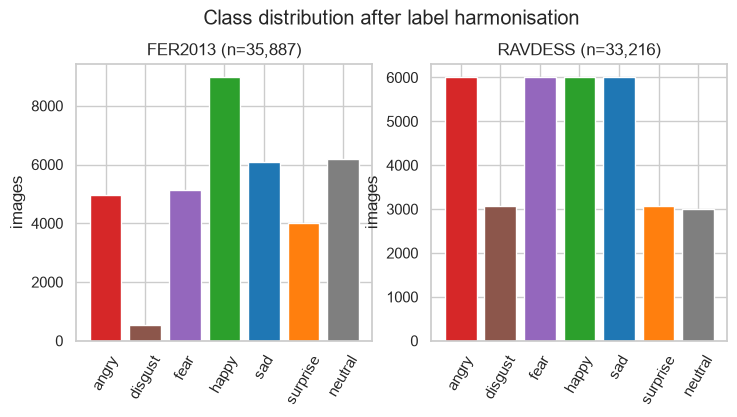

FER2013 class counts per official split:


label,angry,disgust,fear,happy,sad,surprise,neutral
split_official,,,,,,,
PrivateTest,491,55,528,879,594,416,626
PublicTest,467,56,496,895,653,415,607
Training,3995,436,4097,7215,4830,3171,4965


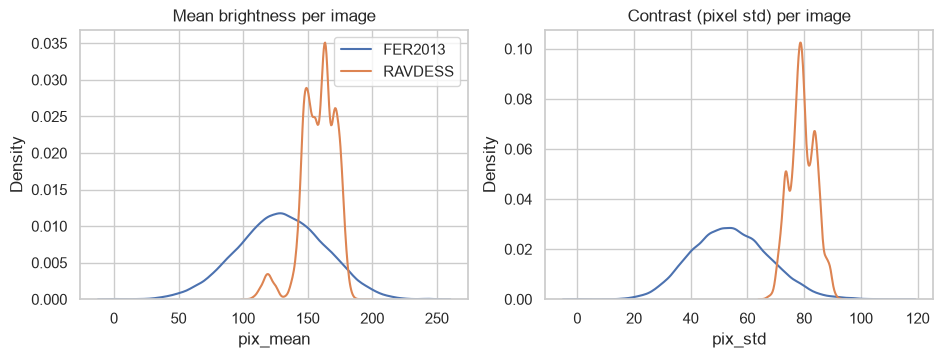

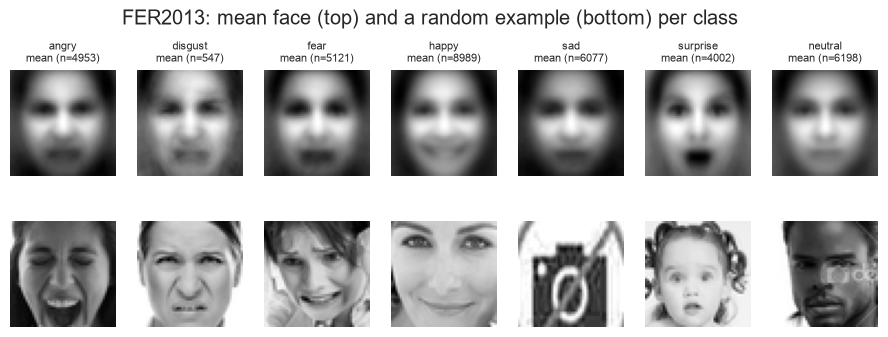

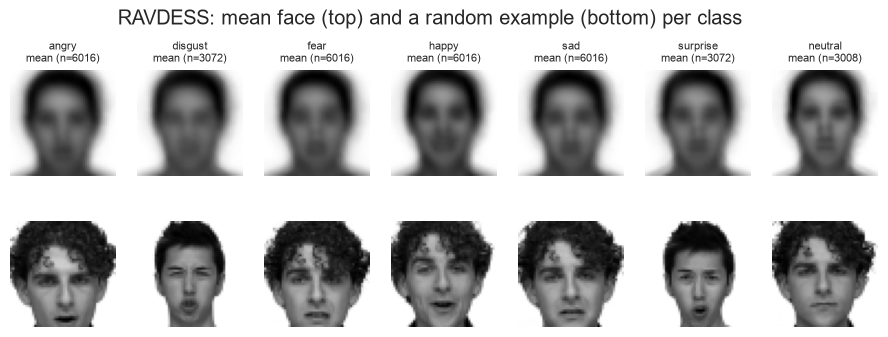

RAVDESS: 24 subjects, 4152 clips, face found in 0.0% of crops


In [5]:
def save_fig(fig, name):
    fig.savefig(OUT / "plots" / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

dist = (META.assign(emotion=META["label"].map(dict(enumerate(CLASSES))))
        .groupby(["dataset", "emotion"]).size().unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0))
summary = dist.copy()
summary["total"] = dist.sum(axis=1)
summary["imbalance (max/min>0)"] = dist.apply(lambda r: r.max() / r[r > 0].min(), axis=1).round(1)
display(summary)
summary.to_csv(OUT / "tables" / "class_distribution.csv")

fig, axes = plt.subplots(1, len(BUNDLES), figsize=(4.2 * len(BUNDLES), 3.6), squeeze=False)
for ax, name in zip(axes[0], BUNDLES):
    row = dist.loc[name]
    ax.bar(CLASSES, row.values, color=[CLASS_COLORS[c] for c in CLASSES])
    ax.set_title(f"{name} (n={row.sum():,})"); ax.tick_params(axis="x", rotation=60)
    ax.set_ylabel("images")
fig.suptitle("Class distribution after label harmonisation", y=1.03)
save_fig(fig, "eda_class_distribution")

fer_m = META[META.dataset == "FER2013"]
ct = pd.crosstab(fer_m["split_official"], fer_m["label"].map(dict(enumerate(CLASSES)))).reindex(columns=CLASSES)
print("FER2013 class counts per official split:"); display(ct)

# image statistics per dataset (domain shift)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name in BUNDLES:
    m = META[META.dataset == name]
    sns.kdeplot(m["pix_mean"], ax=axes[0], label=name, fill=False)
    sns.kdeplot(m["pix_std"], ax=axes[1], label=name, fill=False)
axes[0].set_title("Mean brightness per image"); axes[1].set_title("Contrast (pixel std) per image")
axes[0].legend(); save_fig(fig, "eda_image_statistics")

# mean face per class and example grid for each dataset
for name in BUNDLES:
    m = META[META.dataset == name]
    fig, axes = plt.subplots(2, K, figsize=(1.6 * K, 3.6))
    for j, c in enumerate(CLASSES):
        sel = m[m.label == j]["gidx"].to_numpy()
        for r in range(2):
            axes[r, j].axis("off")
        if len(sel) == 0:
            axes[0, j].set_title(f"{c}\n(none)", fontsize=8); continue
        axes[0, j].imshow(IMAGES[sel].mean(0), cmap="gray"); axes[0, j].set_title(f"{c}\nmean (n={len(sel)})", fontsize=8)
        axes[1, j].imshow(IMAGES[np.random.default_rng(0).choice(sel)], cmap="gray")
    fig.suptitle(f"{name}: mean face (top) and a random example (bottom) per class", y=1.02)
    save_fig(fig, f"eda_faces_{name}")

if HAS_FERPLUS:
    v = fer_m[fer_m.ferplus_valid]
    ent = -np.nansum(SOFT[v.gidx] * np.log(SOFT[v.gidx] + 1e-9), 1)
    agree = (v["label"].to_numpy() == v["ferplus_label"].to_numpy()).mean()
    cm = pd.crosstab(v["label"].map(dict(enumerate(CLASSES))), v["ferplus_label"].map(dict(enumerate(CLASSES))),
                     normalize="index").reindex(index=CLASSES, columns=CLASSES).fillna(0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=axes[0], cbar=False)
    axes[0].set_xlabel("FER+ majority label"); axes[0].set_ylabel("original FER2013 label")
    axes[0].set_title(f"FER2013 vs FER+ (agreement {agree:.1%})")
    axes[1].hist(ent, bins=30, color="#1f77b4"); axes[1].set_title("Entropy of FER+ vote distribution")
    axes[1].set_xlabel("entropy (nats; 0 = all annotators agree)")
    save_fig(fig, "eda_ferplus_agreement")
    print(f"Original FER2013 label equals the FER+ majority for {agree:.1%} of images — a direct measure of label noise.")

for name in EXTERNAL:
    m = META[META.dataset == name]
    print(f"{name}: {m['subject'].nunique()} subjects, {m['video_id'].nunique()} clips, "
          f"face found in {m['face_found'].astype(float).mean():.1%} of crops")

## 5. Splits — leakage-safe and subject-independent where subjects are known

* **FER2013, CSV protocol (recommended):** Training → train, PublicTest → validation, PrivateTest → test.
  This matches the report's best run and most published FER2013 results.
* **FER2013, folder protocol:** a stratified `FOLDER_VAL_FRACTION` of `train/` is validation; the 7,178-image
  `test/` folder is test. FER2013 has no subject IDs, so subject-independence cannot be guaranteed here.
* **CK+, RAVDESS, CREMA-D:** subjects are assigned to train / val / test with `GroupShuffleSplit`; the code
  asserts that no subject appears in two splits.
* The leakage policy from § 3 is then applied to the training split only.

In [6]:
SPLIT_SEED = C.PROJECT_SEED
META["split"] = "unused"
fer_mask = META.dataset == "FER2013"
if FER_PROTOCOL == "csv":
    META.loc[fer_mask, "split"] = META.loc[fer_mask, "split_official"].map(
        {"Training": "train", "PublicTest": "val", "PrivateTest": "test"})
else:
    tr = META[fer_mask & (META.split_official == "Training")]
    tr_i, va_i = train_test_split(tr.index, test_size=C.FOLDER_VAL_FRACTION, stratify=tr["label"], random_state=SPLIT_SEED)
    META.loc[tr_i, "split"] = "train"; META.loc[va_i, "split"] = "val"
    META.loc[fer_mask & (META.split_official == "FolderTest"), "split"] = "test"

for name in EXTERNAL:
    m = META[(META.dataset == name) & META.subject.notna()]
    groups = m["subject"].to_numpy()
    if len(np.unique(groups)) < 3:
        print(f"{name}: fewer than 3 subjects — used only as a zero-shot test set.")
        META.loc[m.index, "split"] = "test"; continue
    tr_f, va_f, te_f = C.EXTERNAL_SPLIT
    gss = GroupShuffleSplit(n_splits=1, test_size=te_f, random_state=SPLIT_SEED)
    trva, te = next(gss.split(m, groups=groups))
    m_trva = m.iloc[trva]
    gss2 = GroupShuffleSplit(n_splits=1, test_size=va_f / (tr_f + va_f), random_state=SPLIT_SEED)
    tr, va = next(gss2.split(m_trva, groups=m_trva["subject"]))
    META.loc[m_trva.index[tr], "split"] = "train"
    META.loc[m_trva.index[va], "split"] = "val"
    META.loc[m.index[te], "split"] = "test"
    subj = {s: set(META[(META.dataset == name) & (META.split == s)].subject) for s in ["train", "val", "test"]}
    assert not (subj["train"] & subj["val"]) and not (subj["train"] & subj["test"]) and not (subj["val"] & subj["test"]), \
        f"subject leakage in {name}"

# ---------------------------------------------------------------- leakage / quality policy (train only)
removed = []
fer = META[fer_mask]
eval_md5 = set(fer[fer.split.isin(["val", "test"])]["md5"])
eval_dh = set(fer[fer.split.isin(["val", "test"])]["dhash"])
trn = fer[fer.split == "train"]
if C.REMOVE_CROSS_SPLIT_DUPLICATES:
    hit = trn[trn["md5"].isin(eval_md5)]
    removed += [(i, "exact duplicate of a val/test image") for i in hit.index]
    conflict_md5 = trn.groupby("md5")["label"].nunique()
    conflict_md5 = set(conflict_md5[conflict_md5 > 1].index)
    hit = trn[trn["md5"].isin(conflict_md5)]
    removed += [(i, "train duplicates with conflicting labels") for i in hit.index]
    # keep a single copy of identical training images with the same label
    hit = trn[trn.duplicated(["md5", "label"], keep="first")]
    removed += [(i, "repeated identical training image") for i in hit.index]
if C.DROP_BLANK_TRAIN_IMAGES:
    removed += [(i, "blank image") for i in trn[trn["blank"]].index]
near_leak = int(trn["dhash"].isin(eval_dh).sum()) if C.NEAR_DUPLICATE_CHECK else 0
rem = pd.DataFrame(removed, columns=["row", "reason"]).drop_duplicates("row")
META.loc[rem["row"], "split"] = "removed"
rem.assign(uid=META.loc[rem["row"], "uid"].to_numpy()).to_csv(OUT / "tables" / "removed_from_train.csv", index=False)
print("Removed from FER2013 train:", rem["reason"].value_counts().to_dict() if len(rem) else "nothing")
print(f"Near-duplicate (dHash) matches between FER2013 train and val/test: {near_leak} (reported, kept)")
lk = META[fer_mask & (META.split == "train")]["md5"].isin(eval_md5).sum()
print(f"Exact train↔val/test duplicates remaining: {lk}")

# ---------------------------------------------------------------- optional subsampling (smoke profile)
def _subsample(mask, per_class, seed=0):
    idx = META[mask].groupby("label", group_keys=False).apply(
        lambda g: g.sample(min(len(g), per_class), random_state=seed)).index
    drop = META[mask].index.difference(idx)
    META.loc[drop, "split"] = "unused"

if P["max_per_class_train"]:
    for name in BUNDLES:
        _subsample((META.dataset == name) & (META.split == "train"), P["max_per_class_train"])
if P["max_per_class_eval"]:
    for name in BUNDLES:
        for sp in ["val", "test"]:
            _subsample((META.dataset == name) & (META.split == sp), P["max_per_class_eval"])

SPLITS = (META[META.split.isin(["train", "val", "test"])]
          .groupby(["dataset", "split"]).size().unstack(fill_value=0).reindex(columns=["train", "val", "test"]))
display(SPLITS)
META[["uid", "dataset", "label", "split", "subject", "video_id"]].to_csv(OUT / "tables" / "split_manifest.csv", index=False)

def gidx(dataset, split, extra=None):
    m = (META.dataset == dataset) & (META.split == split)
    if extra is not None:
        m &= extra
    return META.loc[m, "gidx"].to_numpy()

FER_TRAIN, FER_VAL, FER_TEST = gidx("FER2013", "train"), gidx("FER2013", "val"), gidx("FER2013", "test")
Y_ALL = META.sort_values("gidx")["label"].to_numpy()
assert (META.sort_values("gidx")["gidx"].to_numpy() == np.arange(len(META))).all()
print(f"FER2013: train {len(FER_TRAIN):,} / val {len(FER_VAL):,} / test {len(FER_TEST):,} (test untouched until § H)")

Removed from FER2013 train: {'repeated identical training image': 1021, 'exact duplicate of a val/test image': 703, 'train duplicates with conflicting labels': 73, 'blank image': 1}
Near-duplicate (dHash) matches between FER2013 train and val/test: 767 (reported, kept)
Exact train↔val/test duplicates remaining: 0


split,train,val,test
dataset,,,
FER2013,26911,3589,3589
RAVDESS,21952,5632,5632


FER2013: train 26,911 / val 3,589 / test 3,589 (test untouched until § H)


## 6. Input pipeline: batched augmentation on the device

Images stay as `uint8` on the GPU (FER2013 is about 80 MB) and each batch is augmented with one
`affine_grid` / `grid_sample` call that combines resizing to the model resolution, flip, rotation,
zoom (crop) and translation, followed by brightness/contrast jitter and random erasing.
This removes the CPU data-loading bottleneck and works identically on Windows, Linux and Colab.

| Preset | Used by | Operations |
|---|---|---|
| `report` | the report's recipe | flip, rotation ±10° |
| `weak` | ablation | flip, rotation ±10°, translation ±5 % |
| `strong` | proposed recipe | flip, rotation ±15°, zoom 1.0–1.25 (≈ RandomResizedCrop 64–100 %), translation ±10 %, brightness/contrast ±30 %, random erasing p = 0.25 |

Mixup / CutMix (when enabled) are applied afterwards on the batch and produce soft targets, so the same
soft-target loss handles hard labels, label smoothing, mixing and FER+ vote distributions.

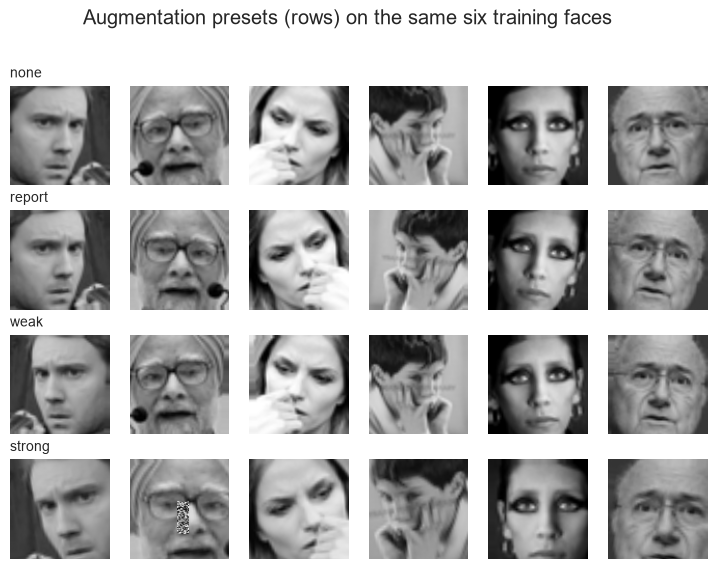

In [7]:
IMG_T = torch.from_numpy(IMAGES)          # (N, S, S) uint8
if DEVICE.type == "cuda":
    IMG_T = IMG_T.to(DEVICE)

_AUG = CONFIG["augmentation"]
AUG_PRESETS = {
    "none":   dict(flip=0.0, rot=0, zoom=(1.0, 1.0), trans=0.0, bright=0.0, contrast=0.0, erase_p=0.0),
    "report": dict(flip=_AUG["horizontal_flip_probability"], rot=_AUG["rotation_degrees"], zoom=(1.0, 1.0), trans=0.0, bright=0.0, contrast=0.0, erase_p=0.0),
    "weak":   dict(flip=_AUG["horizontal_flip_probability"], rot=_AUG["rotation_degrees"], zoom=(1.0, 1.0), trans=_AUG["translation_fraction"] / 2, bright=0.0, contrast=0.0, erase_p=0.0),
    "strong": dict(flip=_AUG["horizontal_flip_probability"], rot=_AUG["rotation_degrees"], zoom=tuple(_AUG["zoom_range"]), trans=_AUG["translation_fraction"], bright=_AUG["brightness_contrast"], contrast=_AUG["brightness_contrast"], erase_p=_AUG["random_erasing_probability"]),
}

def fetch(idx):
    """uint8 images for global indices -> float tensor (B,1,S,S) in [0,1] on DEVICE."""
    t = torch.as_tensor(np.asarray(idx), dtype=torch.long)
    x = IMG_T[t.to(IMG_T.device)] if IMG_T.is_cuda else IMG_T[t]
    return x.to(DEVICE, non_blocking=True).float().div_(255.0).unsqueeze(1)

def resample(x, size, aug=None, gen=None):
    """Resize to `size` and (optionally) apply the geometric + photometric augmentation of a preset."""
    B = x.shape[0]
    dev = x.device
    if aug is None or aug == "none":
        if x.shape[-1] == size:
            return x
        theta = torch.tensor([[1, 0, 0], [0, 1, 0]], dtype=x.dtype, device=dev).expand(B, 2, 3)
    else:
        a = AUG_PRESETS[aug]
        r = lambda *shape: torch.rand(*shape, generator=gen, device="cpu").to(dev)
        ang = (r(B) * 2 - 1) * math.radians(a["rot"])
        zoom = a["zoom"][0] + r(B) * (a["zoom"][1] - a["zoom"][0])
        flip = torch.where(r(B) < a["flip"], -1.0, 1.0).to(dev)
        tx, ty = (r(B) * 2 - 1) * a["trans"] * 2, (r(B) * 2 - 1) * a["trans"] * 2
        cos, sin = torch.cos(ang) / zoom, torch.sin(ang) / zoom
        theta = torch.stack([torch.stack([cos * flip, -sin, tx], 1), torch.stack([sin * flip, cos, ty], 1)], 1).to(x.dtype)
    grid = F.affine_grid(theta, (B, 1, size, size), align_corners=False)
    out = F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)
    if aug not in (None, "none"):
        a = AUG_PRESETS[aug]
        r = lambda *shape: torch.rand(*shape, generator=gen, device="cpu").to(dev)
        if a["bright"] > 0:
            out = out * (1 + (r(B, 1, 1, 1) * 2 - 1) * a["bright"])
        if a["contrast"] > 0:
            mean = out.mean((2, 3), keepdim=True)
            out = (out - mean) * (1 + (r(B, 1, 1, 1) * 2 - 1) * a["contrast"]) + mean
        if a["erase_p"] > 0:
            area = 0.02 + r(B) * 0.13
            asp = torch.exp((r(B) * 2 - 1) * math.log(3))
            eh = (torch.sqrt(area * asp) * size).clamp(1, size).long()
            ew = (torch.sqrt(area / asp) * size).clamp(1, size).long()
            y0 = (r(B) * (size - eh + 1).float()).long()
            x0 = (r(B) * (size - ew + 1).float()).long()
            yy = torch.arange(size, device=dev).view(1, size, 1)
            xx = torch.arange(size, device=dev).view(1, 1, size)
            box = ((yy >= y0.view(-1, 1, 1)) & (yy < (y0 + eh).view(-1, 1, 1)) &
                   (xx >= x0.view(-1, 1, 1)) & (xx < (x0 + ew).view(-1, 1, 1))).unsqueeze(1)
            apply = (r(B) < a["erase_p"]).view(-1, 1, 1, 1)
            out = torch.where(box & apply, r(B, 1, size, size), out)
        out = out.clamp(0, 1)
    return out

def mix_batch(x, t, mixup_alpha, cutmix_alpha, gen):
    """Mixup or CutMix (chosen at random when both are on). t: soft targets (B,K)."""
    use = [m for m, a in (("mixup", mixup_alpha), ("cutmix", cutmix_alpha)) if a > 0]
    if not use:
        return x, t
    kind = use[int(torch.randint(len(use), (1,), generator=gen))]
    alpha = mixup_alpha if kind == "mixup" else cutmix_alpha
    lam = float(np.random.default_rng(int(torch.randint(1 << 30, (1,), generator=gen))).beta(alpha, alpha))
    perm = torch.randperm(x.shape[0], generator=gen).to(x.device)
    if kind == "mixup":
        return lam * x + (1 - lam) * x[perm], lam * t + (1 - lam) * t[perm]
    H = x.shape[-1]
    cut = math.sqrt(1 - lam)
    ch, cw = int(H * cut), int(H * cut)
    cy, cx = int(torch.randint(H, (1,), generator=gen)), int(torch.randint(H, (1,), generator=gen))
    y0, y1 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
    x0, x1 = max(cx - cw // 2, 0), min(cx + cw // 2, H)
    x = x.clone()
    x[:, :, y0:y1, x0:x1] = x[perm][:, :, y0:y1, x0:x1]
    lam = 1 - (y1 - y0) * (x1 - x0) / (H * H)
    return x, lam * t + (1 - lam) * t[perm]

# visual check of the augmentation presets
_demo = fetch(FER_TRAIN[:6])
fig, axes = plt.subplots(4, 6, figsize=(9, 6.2))
for r_, preset in enumerate(["none", "report", "weak", "strong"]):
    g = torch.Generator().manual_seed(r_)
    im = resample(_demo, 96, preset, g).cpu()
    for c_ in range(6):
        axes[r_, c_].imshow(im[c_, 0], cmap="gray", vmin=0, vmax=1); axes[r_, c_].axis("off")
    axes[r_, 0].set_title(preset, loc="left", fontsize=10)
fig.suptitle("Augmentation presets (rows) on the same six training faces", y=1.0)
save_fig(fig, "augmentation_presets")

## 7. Model zoo

| Name | Type | Why it is here |
|---|---|---|
| `tv_resnet50` | torchvision ResNet-50, ImageNet V2 weights | **exact report baseline** (Model A) |
| `resnet18` | timm ResNet-18 | small backbone for fast, controlled recipe ablations |
| `resnet50` | timm ResNet-50 | report's best architecture under the improved recipe (isolates recipe effect) |
| `convnext_tiny` | timm ConvNeXt-T | report's best accuracy/speed balance |
| `efficientnet_b0` / `efficientnet_b2` | timm EfficientNet | lightweight; B0 re-run cleanly (report had conflicting B0 results) |
| `mobilenetv3_large_100` | timm MobileNetV3 | edge/robot deployment candidate |
| `vit_small_patch16_224` | timm ViT-S/16 (positional embeddings resized to the input) | transformer at ¼ the size of the report's ViT-B |
| `hybrid_cnn_transformer` | ResNet-18 stages 1–3 + 2-layer Transformer encoder | local CNN features + global attention between face regions |
| `custom_attn_cnn` / `custom_cnn_noattn` | report's residual CBAM CNN, 48 px grayscale, scratch | report baseline (Model J) and the **missing attention ablation** |
| `hsemotion_enet_b0` *(optional)* | EfficientNet-B0 pretrained on AffectNet faces | face-domain pretraining, if `HSEMOTION_WEIGHTS` is set |

All models take a 1-channel image in [0, 1]; the wrapper repeats it to three channels and applies the
normalisation the backbone was pretrained with, so preprocessing cannot silently mismatch (a suspected
cause of the report's DeepFace collapse).

In [8]:
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class SkipExperiment(Exception):
    pass

class FERNet(nn.Module):
    def __init__(self, backbone, in_chans=3, mean=IMAGENET_MEAN, std=IMAGENET_STD, head=None, fixed_size=None):
        super().__init__()
        self.backbone, self.in_chans, self.head_name, self.fixed_size = backbone, in_chans, head, fixed_size
        self.register_buffer("mean", torch.tensor(mean[:in_chans]).view(1, in_chans, 1, 1))
        self.register_buffer("std", torch.tensor(std[:in_chans]).view(1, in_chans, 1, 1))

    def prep(self, x):
        if self.in_chans == 3 and x.shape[1] == 1:
            x = x.expand(-1, 3, -1, -1)
        return (x - self.mean) / self.std

    def forward(self, x):
        return self.backbone(self.prep(x))

class CBAM(nn.Module):
    def __init__(self, c, r=8):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(c, c // r, 1), nn.ReLU(inplace=True), nn.Conv2d(c // r, c, 1))
        self.spatial = nn.Conv2d(2, 1, 7, padding=3)
    def forward(self, x):
        ca = torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))
        x = x * ca
        sa = torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        return x * sa

class ResBlock(nn.Module):
    def __init__(self, cin, cout, attention=True):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                  nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
        self.att = CBAM(cout) if attention else nn.Identity()
        self.pool = nn.MaxPool2d(2)
    def forward(self, x):
        return self.pool(F.relu(self.att(self.body(x)) + self.skip(x)))

class CustomAttnCNN(nn.Module):
    """Re-implementation of the report's Model J: 32-ch stem, residual blocks 64/128/256 with CBAM, GAP, 128-unit head."""
    def __init__(self, num_classes=K, attention=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.blocks = nn.Sequential(ResBlock(32, 64, attention), ResBlock(64, 128, attention), ResBlock(128, 256, attention))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 128), nn.ReLU(inplace=True),
                                  nn.Dropout(0.3), nn.Linear(128, num_classes))
    def forward_features(self, x):
        return self.blocks(self.stem(x))
    def forward_head(self, f):
        return self.head(F.adaptive_avg_pool2d(f, 1))
    def forward(self, x):
        return self.forward_head(self.forward_features(x))

class HybridCNNTransformer(nn.Module):
    """ResNet-18 up to stride 16 -> tokens -> 2-layer Transformer encoder (global relations between face regions)."""
    def __init__(self, img_size, pretrained, num_classes=K, d=256, layers=2, heads=4):
        super().__init__()
        self.cnn = timm.create_model("resnet18", pretrained=pretrained, features_only=True, out_indices=(3,))
        cin = self.cnn.feature_info.channels()[-1]
        n_tok = max(1, math.ceil(img_size / 16)) ** 2
        self.proj = nn.Conv2d(cin, d, 1)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.zeros(1, n_tok + 1, d))
        nn.init.trunc_normal_(self.pos, std=0.02)
        enc = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(enc, layers)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, num_classes)
    def forward(self, x):
        f = self.proj(self.cnn(x)[-1])
        tok = f.flatten(2).transpose(1, 2)
        tok = torch.cat([self.cls.expand(len(tok), -1, -1), tok], 1)
        pos = self.pos if self.pos.shape[1] == tok.shape[1] else F.interpolate(
            self.pos.transpose(1, 2), size=tok.shape[1], mode="linear").transpose(1, 2)
        z = self.encoder(tok + pos)
        return self.head(self.norm(z[:, 0]))

MODEL_SPECS = {
    "tv_resnet50":            dict(kind="tv", family="cnn"),
    "resnet18":               dict(kind="timm", family="cnn"),
    "resnet50":               dict(kind="timm", family="cnn"),
    "convnext_tiny":          dict(kind="timm", family="cnn"),
    "efficientnetv2_s":       dict(kind="timm", family="cnn"),
    "efficientnet_b0":        dict(kind="timm", family="cnn"),
    "efficientnet_b2":        dict(kind="timm", family="cnn"),
    "mobilenetv3_large_100":  dict(kind="timm", family="cnn"),
    "vit_small_patch16_224":  dict(kind="timm", family="vit"),
    "deit_tiny_patch16_224":  dict(kind="timm", family="vit"),
    "hybrid_cnn_transformer": dict(kind="hybrid", family="vit"),
    "custom_attn_cnn":        dict(kind="custom", family="scratch", attention=True, fixed_size=48),
    "custom_cnn_noattn":      dict(kind="custom", family="scratch", attention=False, fixed_size=48),
}
if C.HSEMOTION_WEIGHTS:
    MODEL_SPECS["hsemotion_enet_b0"] = dict(kind="hsemotion", family="cnn")

def _pretrained_failed(name, err, allow_random):
    msg = f"Pretrained weights for '{name}' could not be loaded ({type(err).__name__}: {str(err)[:120]})."
    if allow_random:
        print("   ", msg, "Continuing with RANDOM weights (smoke profile only; flagged in results).")
        return
    raise SkipExperiment(msg + " Check the internet connection or set on_pretrained_fail='random' "
                         "(results would then not be transfer learning).")

def build_model(name, pretrained, img_size, drop_path=0.0):
    """Returns (FERNet, info). info['pretrained_loaded'] records whether ImageNet/AffectNet weights were really used."""
    spec = MODEL_SPECS[name]
    allow_random = P["on_pretrained_fail"] == "random"
    info = {"pretrained_requested": bool(pretrained), "pretrained_loaded": False}
    if spec["kind"] == "custom":
        net = CustomAttnCNN(K, spec["attention"])
        return FERNet(net, 1, (0.5,), (0.5,), head="head", fixed_size=48), info
    if spec["kind"] == "tv":
        w = None
        if pretrained:
            try:
                w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
                net = torchvision.models.resnet50(weights=w); info["pretrained_loaded"] = True
            except Exception as e:
                _pretrained_failed(name, e, allow_random); net = torchvision.models.resnet50(weights=None)
        else:
            net = torchvision.models.resnet50(weights=None)
        net.fc = nn.Linear(net.fc.in_features, K)
        return FERNet(net, head="fc"), info
    if spec["kind"] == "hybrid":
        try:
            net = HybridCNNTransformer(img_size, pretrained); info["pretrained_loaded"] = bool(pretrained)
        except Exception as e:
            _pretrained_failed(name, e, allow_random); net = HybridCNNTransformer(img_size, False)
        return FERNet(net, head="head"), info
    if spec["kind"] == "hsemotion":
        src = C.HSEMOTION_WEIGHTS
        try:
            if src == "download":
                url = "https://github.com/av-savchenko/face-emotion-recognition/raw/main/models/affectnet_emotions/enet_b0_8_best_vgaf.pt"
                src = OUT / "cache" / "enet_b0_8_best_vgaf.pt"
                if not src.exists():
                    torch.hub.download_url_to_file(url, str(src))
            net = torch.load(src, map_location="cpu", weights_only=False)
            net.classifier = nn.Linear(net.classifier.in_features, K)
            info["pretrained_loaded"] = True
        except Exception as e:
            raise SkipExperiment(f"HSEmotion weights could not be loaded ({e}).")
        return FERNet(net, head="classifier"), info
    kw = dict(num_classes=K)
    if drop_path:
        kw["drop_path_rate"] = drop_path
    if spec["family"] == "vit":
        kw["img_size"] = img_size
    try:
        net = timm.create_model(name, pretrained=pretrained, **kw)
        info["pretrained_loaded"] = bool(pretrained)
    except TypeError:
        kw.pop("drop_path_rate", None)
        net = timm.create_model(name, pretrained=pretrained, **kw); info["pretrained_loaded"] = bool(pretrained)
    except Exception as e:
        if not pretrained:
            raise
        _pretrained_failed(name, e, allow_random)
        net = timm.create_model(name, pretrained=False, **kw)
    cfg = getattr(net, "pretrained_cfg", {}) or {}
    mean, std = cfg.get("mean", IMAGENET_MEAN), cfg.get("std", IMAGENET_STD)
    return FERNet(net, 3, mean, std, head="timm"), info

def head_param_ids(model):
    bb = model.backbone
    if model.head_name == "timm":
        head = bb.get_classifier()
    else:
        head = getattr(bb, model.head_name)
    return {id(p) for p in head.parameters()}

def count_params(model):
    return sum(p.numel() for p in model.parameters())

for _n in ["custom_attn_cnn", "custom_cnn_noattn", "resnet18"]:
    _m, _ = build_model(_n, False, 48)
    print(f"{_n:<22} {count_params(_m) / 1e6:6.2f} M parameters")
del _m

custom_attn_cnn          1.26 M parameters
custom_cnn_noattn        1.24 M parameters
resnet18                11.18 M parameters


## 8. Training engine

One function trains every model. Features: soft-target cross-entropy (handles label smoothing, Mixup/CutMix and FER+
distributions), four imbalance strategies, AdamW with separate head/backbone learning rates, linear warm-up +
cosine decay, EMA weights, gradient clipping, mixed precision, early stopping and checkpoint selection on
**validation macro-F1**, plus:

* **Provenance:** each run folder holds `result.json` (config, config hash, data fingerprint, environment),
  `history.csv`, `best.pt` with its SHA-256, and validation probabilities. Re-running a cell with the same config
  loads the stored result instead of training again.
* **Collapse detector:** a run whose validation predictions put more than 80 % of samples in one class, or whose
  macro-F1 is below 1.5× chance, is flagged `collapsed` (the report's DeepFace and early EfficientNet-B0 failure mode).
* **Test guard:** `predict_split(..., "test")` raises an error until the final selection has been locked in § H.

In [9]:
@dataclass(frozen=True)
class Recipe:
    epochs: int = 20
    batch_size: int = 128
    img_size: int = 112
    aug: str = "strong"
    label_smoothing: float = 0.1
    loss_function: str = "cross_entropy"
    focal_gamma: float = 2.0
    optimizer_name: str = "adamw"
    sgd_momentum: float = 0.9
    imbalance: str = "none"            # none | weighted_ce | balanced_sampler | logit_adjust
    mixup_alpha: float = 0.2
    cutmix_alpha: float = 1.0
    mix_prob: float = 0.5
    mix_off_last_frac: float = 0.15
    lr_backbone: float = None          # None -> family default
    lr_head: float = None
    weight_decay: float = 0.05
    schedule: str = "cosine"           # cosine | constant
    warmup_epochs: float = 1.0
    ema_decay: float = 0.999           # 0 = off
    grad_clip: float = 1.0
    drop_path: float = 0.1
    patience: int = 8
    regime: str = "finetune"           # finetune | linear_probe | scratch
    label_source: str = "fer2013"      # fer2013 | ferplus_soft
    imbalance_power: float = None      # None -> config.IMBALANCE_POWER

FAMILY_LR = {"cnn": (3e-4, 1e-3), "vit": (1e-4, 1e-3), "scratch": (1e-3, 1e-3)}

def effective_lrs(model_name, rc):
    fam = MODEL_SPECS[model_name]["family"]
    if rc.regime == "scratch" and fam != "scratch":
        fam = "scratch"
    lb, lh = FAMILY_LR[fam]
    if rc.regime == "linear_probe":
        lb, lh = 0.0, 1e-2
    return (rc.lr_backbone if rc.lr_backbone is not None else lb), (rc.lr_head if rc.lr_head is not None else lh)

def soft_ce(logits, target, weights=None, loss_function="cross_entropy", focal_gamma=2.0):
    log_probs = F.log_softmax(logits.float(), 1)
    loss = -(target * log_probs).sum(1)
    if loss_function == "focal":
        p_true = (target * log_probs.exp()).sum(1).clamp_min(1e-8)
        loss = loss * (1 - p_true).pow(focal_gamma)
    elif loss_function != "cross_entropy":
        raise ValueError(f"Unsupported loss function: {loss_function!r}")
    if weights is not None:
        loss = loss * (target * weights).sum(1)
    return loss.mean()

class ModelEMA:
    def __init__(self, model, decay):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])

@torch.no_grad()
def predict_probs(model, idx, img_size, tta=False, batch=512, perturb=None):
    """Softmax probabilities for global indices. `perturb` acts on [0,1] pixels at native size (robustness)."""
    model.eval()
    size = model.fixed_size or img_size
    out = []
    for s in range(0, len(idx), batch):
        x = fetch(idx[s:s + batch])
        if perturb is not None:
            x = perturb(x)
        x = resample(x, size)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = F.softmax(model(x).float(), 1)
            if tta:
                p = (p + F.softmax(model(torch.flip(x, dims=[3])).float(), 1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, K), np.float32)

def ece_score(y, probs, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return float(e)

def compute_metrics(y, probs, labels=None, restrict=False):
    """labels: classes to score (default all 7). restrict=True: argmax only over `labels` (closed-set evaluation)."""
    labels = list(range(K)) if labels is None else list(labels)
    p = probs.copy()
    if restrict:
        mask = np.full(K, -np.inf); mask[labels] = 0
        p = p + mask
    pred = p.argmax(1)
    prec, rec, f1, sup = precision_recall_fscore_support(y, pred, labels=labels, zero_division=0)
    yi = np.clip(y, 0, K - 1)
    nll = float(-np.log(np.clip(probs[np.arange(len(y)), yi], 1e-9, 1)).mean())
    return {"acc": accuracy_score(y, pred), "bal_acc": float(np.mean(rec)),
            "macro_f1": float(np.mean(f1)), "weighted_f1": f1_score(y, pred, labels=labels, average="weighted", zero_division=0),
            "macro_precision": float(np.mean(prec)), "macro_recall": float(np.mean(rec)),
            "nll": nll, "ece": ece_score(y, probs),
            "per_class": {CLASSES[l]: {"precision": float(a), "recall": float(b), "f1": float(c), "support": int(d)}
                          for l, a, b, c, d in zip(labels, prec, rec, f1, sup)},
            "cm": confusion_matrix(y, pred, labels=labels).tolist(), "pred": pred}

def _fingerprint(idx):
    uids = META.sort_values("gidx")["uid"].to_numpy()[np.asarray(idx, np.int64)]
    return hashlib.md5("|".join(map(str, uids)).encode()).hexdigest()[:12]

def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

RUNS = {}   # exp_id -> result dict

def run_experiment(exp_id, model_name, rc: Recipe, train_idx, val_idx, seed=0, val_labels=None, stage="", note=""):
    """Train (or load from cache) one model. Returns the result dict. Never touches test data."""
    train_idx, val_idx = np.asarray(train_idx), np.asarray(val_idx)
    val_y = Y_ALL[val_idx] if val_labels is None else np.asarray(val_labels)
    pretrained = (CONFIG["initialization"]["pretrained_default"] and rc.regime != "scratch"
                  and MODEL_SPECS[model_name]["family"] != "scratch")
    lr_b, lr_h = effective_lrs(model_name, rc)
    cfg = {"model": model_name, "recipe": asdict(rc), "seed": seed, "pretrained": pretrained,
           "lr_backbone": lr_b, "lr_head": lr_h, "train_fp": _fingerprint(train_idx), "val_fp": _fingerprint(val_idx),
           "code": CODE_VERSION, "profile": C.RUN_PROFILE}
    cfg_hash = hashlib.sha1(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:12]
    for other in RUNS.values():   # identical configuration already trained under another name
        if other.get("cfg_hash") == cfg_hash:
            print(f"[reuse] {exp_id} = {other['exp_id']} (identical configuration)")
            RUNS[exp_id] = other
            return other
    rdir = OUT / "runs" / exp_id
    if (rdir / "result.json").exists():
        old = json.loads((rdir / "result.json").read_text())
        if old.get("cfg_hash") == cfg_hash and (rdir / "best.pt").exists():
            old["val_probs"] = np.load(rdir / "val_probs.npy")
            RUNS[exp_id] = old
            print(f"[cache] {exp_id}: val macro-F1 {old['val']['macro_f1']:.4f}")
            return old
        raise FileExistsError(f"Run directory {rdir} contains a different experiment. Use a new experiment ID/output directory to preserve it.")
    if rdir.exists() and any(rdir.iterdir()):
        raise FileExistsError(f"Run directory {rdir} is non-empty but has no reusable result. Use a new experiment ID to preserve it.")
    rdir.mkdir(parents=True, exist_ok=True)
    seed_everything(seed)
    gen = torch.Generator().manual_seed(seed)
    try:
        model, info = build_model(model_name, pretrained, rc.img_size, rc.drop_path)
    except SkipExperiment as e:
        print(f"[skip] {exp_id}: {e}")
        return None
    model = model.to(DEVICE)
    size = model.fixed_size or rc.img_size

    # ---- targets (soft, K-dim)
    if rc.label_source == "ferplus_soft":
        tgt = SOFT[train_idx].copy()
        ok = ~np.isnan(tgt).any(1)
        train_idx, tgt = train_idx[ok], tgt[ok]
    else:
        tgt = np.eye(K, dtype=np.float32)[Y_ALL[train_idx]]
    hard = tgt.argmax(1)
    counts = np.maximum(tgt.sum(0), 1e-6)
    prior = counts / counts.sum()
    power = C.IMBALANCE_POWER if rc.imbalance_power is None else rc.imbalance_power
    cls_w = torch.tensor((1 / prior) ** power, dtype=torch.float32, device=DEVICE)
    cls_w = cls_w / (cls_w * torch.tensor(prior, device=DEVICE, dtype=torch.float32)).sum()
    log_prior = torch.tensor(np.log(prior), dtype=torch.float32, device=DEVICE)
    tgt_t = torch.tensor(tgt, device=DEVICE)

    # ---- trainable parameters / optimiser
    head_ids = head_param_ids(model)
    if rc.regime == "linear_probe":
        for p in model.parameters():
            p.requires_grad_(id(p) in head_ids)
    params_head = [p for p in model.parameters() if id(p) in head_ids and p.requires_grad]
    params_body = [p for p in model.parameters() if id(p) not in head_ids and p.requires_grad]
    groups = [{"params": params_head, "lr": lr_h}]
    if params_body and lr_b > 0:
        groups.append({"params": params_body, "lr": lr_b})
    if rc.optimizer_name == "adamw":
        opt = torch.optim.AdamW(groups, weight_decay=rc.weight_decay)
    elif rc.optimizer_name == "adam":
        opt = torch.optim.Adam(groups, weight_decay=rc.weight_decay)
    elif rc.optimizer_name == "sgd":
        opt = torch.optim.SGD(groups, weight_decay=rc.weight_decay, momentum=rc.sgd_momentum)
    else:
        raise ValueError(f"Unsupported optimizer: {rc.optimizer_name!r}")
    base_lrs = [g["lr"] for g in opt.param_groups]
    steps_per_epoch = max(1, len(train_idx) // rc.batch_size)
    total, warm = rc.epochs * steps_per_epoch, int(rc.warmup_epochs * steps_per_epoch)
    def lr_factor(step):
        if rc.schedule == "constant":
            return 1.0
        if step < warm:
            return (step + 1) / max(1, warm)
        prog = (step - warm) / max(1, total - warm)
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    ema = ModelEMA(model, rc.ema_decay) if rc.ema_decay > 0 else None

    # ---- sampler
    if rc.imbalance == "balanced_sampler":
        sw = ((1 / prior) ** power)[hard]
        sw = torch.tensor(sw / sw.sum(), dtype=torch.float64)

    hist, best, bad, step = [], -1.0, 0, 0
    t_start = time.time()
    print(f"[train] {exp_id}: {model_name} | {count_params(model) / 1e6:.1f}M params | {size}px | "
          f"pretrained={info['pretrained_loaded']} | lr {lr_b:g}/{lr_h:g} | n_train={len(train_idx):,}")
    for epoch in range(1, rc.epochs + 1):
        model.train()
        if rc.regime == "linear_probe":
            for m in model.modules():
                if isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                    m.eval()
        if rc.imbalance == "balanced_sampler":
            order = torch.multinomial(sw, len(train_idx), replacement=True, generator=gen).numpy()
        else:
            order = torch.randperm(len(train_idx), generator=gen).numpy()
        mixing_on = epoch <= rc.epochs * (1 - rc.mix_off_last_frac)
        t_ep, tot_loss, tot_ok, tot_n = time.time(), 0.0, 0, 0
        for b in range(steps_per_epoch):
            sel = order[b * rc.batch_size:(b + 1) * rc.batch_size]
            x = resample(fetch(train_idx[sel]), size, rc.aug, gen)
            t = tgt_t[torch.as_tensor(sel, device=DEVICE)]
            yb = t.argmax(1)
            if rc.label_smoothing > 0:
                t = t * (1 - rc.label_smoothing) + rc.label_smoothing / K
            if mixing_on and float(torch.rand(1, generator=gen)) < rc.mix_prob:
                x, t = mix_batch(x, t, rc.mixup_alpha, rc.cutmix_alpha, gen)
            for g, base in zip(opt.param_groups, base_lrs):
                g["lr"] = base * lr_factor(step)
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            if rc.imbalance == "logit_adjust":
                loss = soft_ce(logits.float() + log_prior, t, loss_function=rc.loss_function,
                               focal_gamma=rc.focal_gamma)
            else:
                loss = soft_ce(logits, t, cls_w if rc.imbalance == "weighted_ce" else None,
                               loss_function=rc.loss_function, focal_gamma=rc.focal_gamma)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"{exp_id}: non-finite loss at epoch {epoch}; lower the learning rate.")
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if rc.grad_clip:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], rc.grad_clip)
            scaler.step(opt); scaler.update()
            if ema is not None:
                ema.update(model)
            step += 1
            tot_loss += loss.item() * len(sel); tot_n += len(sel)
            tot_ok += (logits.argmax(1) == yb).sum().item()
        eval_model = ema.ema if ema is not None else model
        vp = predict_probs(eval_model, val_idx, size)
        vm = compute_metrics(val_y, vp)
        hist.append({"epoch": epoch, "train_loss": tot_loss / max(tot_n, 1), "train_acc": tot_ok / max(tot_n, 1),
                     "val_loss": vm["nll"], "val_acc": vm["acc"], "val_macro_f1": vm["macro_f1"],
                     "lr": opt.param_groups[0]["lr"], "sec": time.time() - t_ep})
        improved = vm["macro_f1"] > best + 1e-4
        if improved:
            best, bad = vm["macro_f1"], 0
            torch.save({"state_dict": eval_model.state_dict(), "model": model_name, "img_size": rc.img_size,
                        "recipe": asdict(rc), "epoch": epoch, "classes": CLASSES}, rdir / "best.pt")
            np.save(rdir / "val_probs.npy", vp.astype(np.float32))
        else:
            bad += 1
        print(f"   ep {epoch:>2} loss {hist[-1]['train_loss']:.3f} acc {hist[-1]['train_acc']:.3f} | val acc "
              f"{vm['acc']:.4f} mF1 {vm['macro_f1']:.4f}{' *' if improved else ''} | {hist[-1]['sec']:.0f}s")
        if bad >= rc.patience:
            print(f"   early stop (no val macro-F1 gain for {rc.patience} epochs)")
            break
    vp = np.load(rdir / "val_probs.npy")
    vm = compute_metrics(val_y, vp)
    share = np.bincount(vm["pred"], minlength=K).max() / len(vm["pred"])
    collapsed = bool(share > 0.8 or vm["macro_f1"] < 1.5 / K)
    pd.DataFrame(hist).to_csv(rdir / "history.csv", index=False)
    res = {"exp_id": exp_id, "stage": stage, "note": note, "model": model_name, "seed": seed, "cfg": cfg,
           "cfg_hash": cfg_hash, "recipe": asdict(rc), "pretrained_loaded": info["pretrained_loaded"],
           "params_m": count_params(model) / 1e6, "best_epoch": int(pd.DataFrame(hist)["val_macro_f1"].idxmax()) + 1,
           "epochs_run": len(hist), "train_minutes": (time.time() - t_start) / 60,
           "val": {k: v for k, v in vm.items() if k != "pred"}, "collapsed": collapsed,
           "max_class_share": float(share), "ckpt_sha256": _sha256(rdir / "best.pt"),
           "env": {"device": str(DEVICE), "gpu": MANIFEST["gpu"], "torch": torch.__version__, "timm": timm.__version__}}
    (rdir / "result.json").write_text(json.dumps(res, indent=1, default=float))
    res["val_probs"] = vp
    RUNS[exp_id] = res
    flag = "  ⚠ COLLAPSED" if collapsed else ""
    print(f"   -> best val macro-F1 {vm['macro_f1']:.4f} (acc {vm['acc']:.4f}) at epoch {res['best_epoch']}, "
          f"{res['train_minutes']:.1f} min{flag}")
    return res

def load_model(exp_id):
    r = RUNS[exp_id]
    ck = torch.load(OUT / "runs" / exp_id / "best.pt", map_location="cpu", weights_only=False)
    m, _ = build_model(r["model"], False, ck["img_size"], r["recipe"]["drop_path"])
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval()

SELECTION = None  # set and locked in § H

def predict_split(exp_id, split_idx, split_name, tta=False, perturb=None):
    if split_name == "test" and SELECTION is None:
        raise PermissionError("Test data is locked until the final model is selected on validation data (§ H).")
    model = load_model(exp_id)
    return predict_probs(model, split_idx, RUNS[exp_id]["recipe"]["img_size"], tta=tta, perturb=perturb)

def runs_table(ids=None):
    rows, seen = [], set()
    for k, r in RUNS.items():
        if r is None or (ids is not None and k not in ids) or id(r) in seen:
            continue
        seen.add(id(r))
        rc = r["recipe"]
        rows.append({"exp_id": r["exp_id"], "stage": r["stage"], "model": r["model"], "regime": rc["regime"],
                     "labels": rc["label_source"], "img": rc["img_size"], "seed": r["seed"],
                     "val_acc": r["val"]["acc"], "val_macro_f1": r["val"]["macro_f1"],
                     "val_bal_acc": r["val"]["bal_acc"], "val_ece": r["val"]["ece"], "best_ep": r["best_epoch"],
                     "minutes": r["train_minutes"], "params_M": r["params_m"],
                     "pretrained": r["pretrained_loaded"], "collapsed": r["collapsed"], "note": r["note"]})
    return pd.DataFrame(rows)

## Stage A — Reproduce the report's baselines under the shared protocol

**A1** is the report's best model (Model A) with its exact recipe: torchvision ResNet-50 (ImageNet V2), plain
cross-entropy, AdamW 1e-4, weight decay 1e-4, batch 32, 224 px, flip + 10° rotation, constant learning rate,
checkpoint on validation macro-F1. **A2** is the report's from-scratch custom CBAM CNN (Model J): 48 px grayscale,
inverse-frequency weighted cross-entropy, learning rate 1e-3.

The report's own figures are printed for orientation only: A2 in the report used a different (7,178-image) test set,
and none of the report's numbers is used for any decision below.

In [10]:
REPORTED = pd.DataFrame([
    {"model": "ResNet-50 (report Model A)", "test split in report": "PrivateTest 3,589", "test acc": 72.14, "test macro-F1": 0.7093},
    {"model": "ViT-B/16 (report Model B)", "test split in report": "PrivateTest 3,589", "test acc": 71.41, "test macro-F1": 0.7116},
    {"model": "ConvNeXt-Tiny (report Model F)", "test split in report": "folder 7,178", "test acc": 69.38, "test macro-F1": 0.6657},
    {"model": "Custom attention CNN (report Model J)", "test split in report": "folder 7,178", "test acc": 61.28, "test macro-F1": 0.5797},
])
print("Reported in the comparative report (reference only, different runs/protocols):")
display(REPORTED)

BASE_IMG = P["img_size"] if C.RUN_PROFILE == "smoke" else 224
REPORT_RECIPE = Recipe(epochs=P["epochs_baseline"], batch_size=32, img_size=BASE_IMG, aug="report",
                       label_smoothing=0.0, imbalance="none", mixup_alpha=0.0, cutmix_alpha=0.0,
                       lr_backbone=1e-4, lr_head=1e-4, weight_decay=1e-4, schedule="constant", warmup_epochs=0,
                       ema_decay=0.0, grad_clip=0.0, drop_path=0.0, patience=P["patience"])
REPORT_CNN_RECIPE = Recipe(epochs=P["epochs_baseline"], batch_size=64, img_size=48, aug="weak",
                           label_smoothing=0.0, imbalance="weighted_ce", imbalance_power=1.0,
                           mixup_alpha=0.0, cutmix_alpha=0.0, lr_backbone=1e-3, lr_head=1e-3, weight_decay=0.0,
                           schedule="constant", warmup_epochs=0, ema_decay=0.0, grad_clip=0.0, drop_path=0.0,
                           patience=P["patience"], regime="scratch")
A1 = A2 = None
if C.RUN_STAGES["baseline_reproduction"]:
    A1 = run_experiment("A1_report_resnet50", "tv_resnet50", REPORT_RECIPE, FER_TRAIN, FER_VAL, stage="A",
                        note="report recipe, Model A")
    A2 = run_experiment("A2_report_custom_cnn", "custom_attn_cnn", REPORT_CNN_RECIPE, FER_TRAIN, FER_VAL, stage="A",
                        note="report recipe, Model J")
    display(runs_table([k for k in ["A1_report_resnet50", "A2_report_custom_cnn"] if k in RUNS]))
BASELINE_ID = "A1_report_resnet50" if A1 else ("A2_report_custom_cnn" if A2 else None)

Reported in the comparative report (reference only, different runs/protocols):


,model,test split in report,test acc,test macro-F1
0,ResNet-50 (report Model A),"PrivateTest 3,589",72.14,0.7093
1,ViT-B/16 (report Model B),"PrivateTest 3,589",71.41,0.7116
2,ConvNeXt-Tiny (report Model F),"folder 7,178",69.38,0.6657
3,Custom attention CNN (report Model J),"folder 7,178",61.28,0.5797


[train] A1_report_resnet50: tv_resnet50 | 23.5M params | 224px | pretrained=True | lr 0.0001/0.0001 | n_train=26,911
   ep  1 loss 1.240 acc 0.524 | val acc 0.5996 mF1 0.5142 * | 4955s
   ep  2 loss 0.957 acc 0.641 | val acc 0.6467 mF1 0.5851 * | 3556s
   ep  3 loss 0.840 acc 0.685 | val acc 0.6573 mF1 0.5994 * | 4180s
   ep  4 loss 0.740 acc 0.729 | val acc 0.6539 mF1 0.6080 * | -3646s
   ep  5 loss 0.648 acc 0.761 | val acc 0.6695 mF1 0.6276 * | 3558s
   ep  6 loss 0.547 acc 0.801 | val acc 0.6615 mF1 0.6216 | 7258s
   ep  7 loss 0.456 acc 0.835 | val acc 0.6712 mF1 0.6467 * | 3587s
   ep  8 loss 0.381 acc 0.863 | val acc 0.6520 mF1 0.6147 | 3571s
   ep  9 loss 0.317 acc 0.886 | val acc 0.6598 mF1 0.6400 | 6892s
   ep 10 loss 0.272 acc 0.903 | val acc 0.6559 mF1 0.6288 | 3591s
   ep 11 loss 0.234 acc 0.917 | val acc 0.6701 mF1 0.6308 | 3748s
   ep 12 loss 0.205 acc 0.928 | val acc 0.6721 mF1 0.6413 | 3907s
   ep 13 loss 0.179 acc 0.938 | val acc 0.6682 mF1 0.6311 | 3561s
   early sto

,exp_id,stage,model,regime,labels,img,seed,val_acc,val_macro_f1,val_bal_acc,val_ece,best_ep,minutes,params_M,pretrained,collapsed,note
0,A1_report_resnet50,A,tv_resnet50,finetune,fer2013,224,0,0.671218,0.646716,0.633709,0.127515,7,811.993165,23.522375,True,False,"report recipe, Model A"
1,A2_report_custom_cnn,A,custom_attn_cnn,scratch,fer2013,48,0,0.536918,0.477808,0.528423,0.012481,14,107.577746,1.263368,False,False,"report recipe, Model J"


## Stage B — Which training components actually help? (validation only)

All runs use the same small backbone (`ABLATION_BACKBONE`, ResNet-18 by default) so that many variants are
affordable. **B1** is the proposed recipe; each later run removes or swaps **one** component.

* A component is **kept** only if removing it lowers validation macro-F1 by more than `IMPROVEMENT_TOLERANCE`;
  otherwise the simpler recipe wins.
* The imbalance strategy and input resolution are chosen the same way (a more complex/expensive option must beat
  the simple one by more than the tolerance).
* The assembled recipe is then trained once more (**B_final**) to confirm it, because components can interact.
* Limitation: one seed per ablation, so small deltas are within noise; the tolerance guards against chasing it.

[train] B0_report_recipe: resnet18 | 11.2M params | 112px | pretrained=True | lr 0.0001/0.0001 | n_train=26,911
   ep  1 loss 1.556 acc 0.391 | val acc 0.4923 mF1 0.3749 * | 483s
   ep  2 loss 1.241 acc 0.527 | val acc 0.5478 mF1 0.4348 * | 532s
   ep  3 loss 1.130 acc 0.570 | val acc 0.5759 mF1 0.4690 * | 594s
   ep  4 loss 1.052 acc 0.604 | val acc 0.5899 mF1 0.4885 * | 611s
   ep  5 loss 0.994 acc 0.628 | val acc 0.6043 mF1 0.5135 * | 602s
   ep  6 loss 0.942 acc 0.646 | val acc 0.6127 mF1 0.5276 * | 609s
   ep  7 loss 0.894 acc 0.667 | val acc 0.6172 mF1 0.5473 * | 605s
   ep  8 loss 0.851 acc 0.683 | val acc 0.6247 mF1 0.5581 * | 610s
   ep  9 loss 0.804 acc 0.704 | val acc 0.6314 mF1 0.5790 * | 616s
   ep 10 loss 0.762 acc 0.717 | val acc 0.6308 mF1 0.5779 | 589s
   ep 11 loss 0.725 acc 0.730 | val acc 0.6319 mF1 0.5876 * | 610s
   ep 12 loss 0.682 acc 0.751 | val acc 0.6378 mF1 0.5874 | 612s
   -> best val macro-F1 0.5876 (acc 0.6319) at epoch 11, 117.9 min
[train] B1_proposed: 

,component,val macro-F1 without it,contribution (B1 - variant),decision
0,label smoothing,0.525332,0.006506,keep
1,Mixup/CutMix,0.543025,-0.011187,drop
2,strong augmentation,0.553132,-0.021294,drop
3,warm-up + cosine schedule,0.582853,-0.051015,drop
4,EMA weights,0.535029,-0.003191,drop
5,imbalance strategy,0.531838,0.048553,balanced_sampler (best: balanced_sampler)


[train] B_final_assembled: resnet18 | 11.2M params | 112px | pretrained=True | lr 0.0003/0.001 | n_train=26,911
   ep  1 loss 1.665 acc 0.383 | val acc 0.5029 mF1 0.3988 * | 286s
   ep  2 loss 1.438 acc 0.505 | val acc 0.5600 mF1 0.5046 * | 3227s
   ep  3 loss 1.338 acc 0.559 | val acc 0.5832 mF1 0.5247 * | 283s
   ep  4 loss 1.275 acc 0.593 | val acc 0.6016 mF1 0.5552 * | 288s
   ep  5 loss 1.225 acc 0.617 | val acc 0.6027 mF1 0.5622 * | 284s
   ep  6 loss 1.190 acc 0.638 | val acc 0.6091 mF1 0.5813 * | 283s
   ep  7 loss 1.152 acc 0.659 | val acc 0.6169 mF1 0.5783 | 288s
   ep  8 loss 1.114 acc 0.677 | val acc 0.6258 mF1 0.6028 * | 281s
   ep  9 loss 1.081 acc 0.696 | val acc 0.6275 mF1 0.6040 * | 287s
   ep 10 loss 1.057 acc 0.709 | val acc 0.6275 mF1 0.5951 | 284s
   ep 11 loss 1.037 acc 0.721 | val acc 0.6358 mF1 0.6088 * | 283s
   ep 12 loss 1.013 acc 0.735 | val acc 0.6364 mF1 0.6102 * | 288s
   -> best val macro-F1 0.6102 (acc 0.6364) at epoch 12, 106.0 min
Assembled recipe val

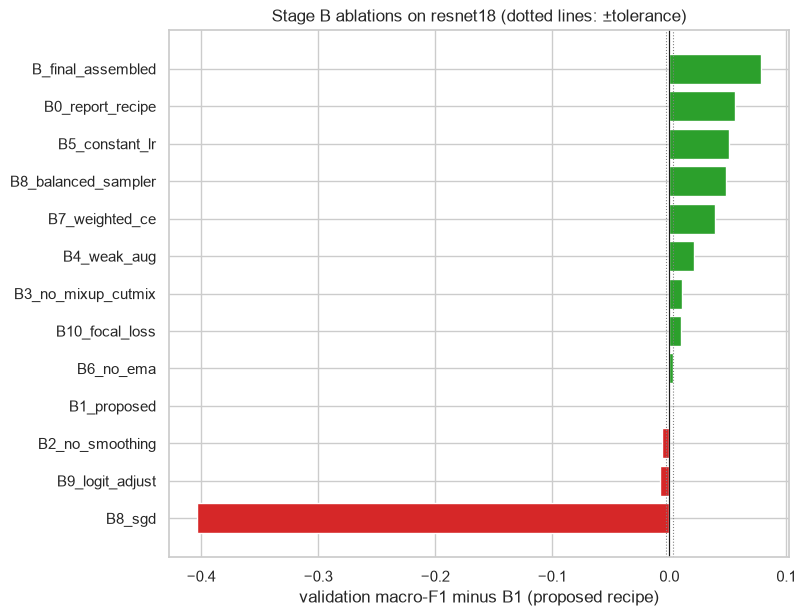

FINAL_RECIPE: Recipe(epochs=12, batch_size=128, img_size=112, aug='weak', label_smoothing=0.1, loss_function='cross_entropy', focal_gamma=2.0, optimizer_name='adamw', sgd_momentum=0.9, imbalance='balanced_sampler', mixup_alpha=0.0, cutmix_alpha=0.0, mix_prob=0.5, mix_off_last_frac=0.15, lr_backbone=None, lr_head=None, weight_decay=0.05, schedule='constant', warmup_epochs=0, ema_decay=0.0, grad_clip=1.0, drop_path=0.1, patience=6, regime='finetune', label_source='fer2013', imbalance_power=None)


In [11]:
AB = C.ABLATION_BACKBONE
TOL = C.IMPROVEMENT_TOLERANCE
PROPOSED = Recipe(epochs=P["epochs_ablation"], batch_size=P["batch_size"], img_size=P["img_size"], patience=P["patience"],
                  label_smoothing=CONFIG["loss"]["label_smoothing"], loss_function=CONFIG["loss"]["default"],
                  focal_gamma=CONFIG["loss"]["focal_gamma"], optimizer_name=CONFIG["optimizer"]["name"],
                  sgd_momentum=CONFIG["optimizer"]["sgd_momentum"],
                  aug="strong" if CONFIG["augmentation"]["enabled"] else "none",
                  mixup_alpha=CONFIG["augmentation"]["mixup_alpha"],
                  cutmix_alpha=CONFIG["augmentation"]["cutmix_alpha"],
                  mix_prob=CONFIG["augmentation"]["mix_probability"],
                  lr_backbone=CONFIG["optimizer"]["learning_rate_backbone"],
                  lr_head=CONFIG["optimizer"]["learning_rate_head"],
                  weight_decay=CONFIG["optimizer"]["weight_decay"],
                  schedule=CONFIG["scheduler"]["name"], warmup_epochs=CONFIG["scheduler"]["warmup_epochs"],
                  grad_clip=CONFIG["optimizer"]["gradient_clip_norm"])

def vf1(res):
    return res["val"]["macro_f1"] if res else float("nan")

ABL = {}
FINAL_RECIPE = PROPOSED
USE_TTA = False
if C.RUN_STAGES["recipe_ablation"]:
    comparisons = ENABLED_COMPARISONS
    variants = {
        "B0_report_recipe":  replace(REPORT_RECIPE, img_size=P["img_size"], epochs=P["epochs_ablation"]),
        "B1_proposed":       PROPOSED,
        "B2_no_smoothing":   replace(PROPOSED, label_smoothing=0.0),
        "B3_no_mixup_cutmix": replace(PROPOSED, mixup_alpha=0.0, cutmix_alpha=0.0),
        **({"B4_weak_aug": replace(PROPOSED, aug="weak")} if "baseline_vs_augmentation" in comparisons else {}),
        "B5_constant_lr":    replace(PROPOSED, schedule="constant", warmup_epochs=0),
        "B6_no_ema":         replace(PROPOSED, ema_decay=0.0),
        **({"B8_sgd": replace(PROPOSED, optimizer_name="sgd")} if "adamw_vs_sgd" in comparisons else {}),
        **({"B7_weighted_ce": replace(PROPOSED, imbalance="weighted_ce")} if "weighted_loss" in comparisons else {}),
        **({"B10_focal_loss": replace(PROPOSED, loss_function="focal")} if CONFIG["loss"]["compare_cross_entropy_and_focal"] and "cross_entropy_vs_focal" in comparisons else {}),
        **({"B8_balanced_sampler": replace(PROPOSED, imbalance="balanced_sampler"),
            "B9_logit_adjust": replace(PROPOSED, imbalance="logit_adjust")} if "weighted_loss" in comparisons else {}),
    }
    for s_ in (P["img_size_candidates"] if "input_resolution" in comparisons else []):
        if s_ != P["img_size"]:
            variants[f"B10_img{s_}"] = replace(PROPOSED, img_size=s_)
    for vid, rc in variants.items():
        ABL[vid] = run_experiment(vid, AB, rc, FER_TRAIN, FER_VAL, stage="B", note=vid.split("_", 1)[1])

    if ABL.get("B1_proposed") is None:
        print("B1 could not run (pretrained weights unavailable?) — keeping the proposed recipe without ablation evidence.")
    else:
        base = vf1(ABL["B1_proposed"])
        removable = {"label smoothing": ("B2_no_smoothing", dict(label_smoothing=0.0)),
                     "Mixup/CutMix": ("B3_no_mixup_cutmix", dict(mixup_alpha=0.0, cutmix_alpha=0.0)),
                     "strong augmentation": ("B4_weak_aug", dict(aug="weak")),
                     "warm-up + cosine schedule": ("B5_constant_lr", dict(schedule="constant", warmup_epochs=0)),
                     "EMA weights": ("B6_no_ema", dict(ema_decay=0.0))}
        decisions, changes = [], {}
        for comp, (vid, chg) in removable.items():
            if ABL.get(vid) is None:
                continue
            delta = base - vf1(ABL[vid])
            keep = delta > TOL
            decisions.append({"component": comp, "val macro-F1 without it": vf1(ABL[vid]),
                              "contribution (B1 - variant)": delta, "decision": "keep" if keep else "drop"})
            if not keep:
                changes.update(chg)
        imb = {"none": base}
        for name, vid in [("weighted_ce", "B7_weighted_ce"), ("balanced_sampler", "B8_balanced_sampler"),
                          ("logit_adjust", "B9_logit_adjust")]:
            if ABL.get(vid) is not None:
                imb[name] = vf1(ABL[vid])
        best_imb = max(imb, key=imb.get)
        if best_imb != "none" and imb[best_imb] - imb["none"] > TOL:
            changes["imbalance"] = best_imb
        decisions.append({"component": "imbalance strategy", "val macro-F1 without it": imb["none"],
                          "contribution (B1 - variant)": imb[best_imb] - imb["none"],
                          "decision": changes.get("imbalance", "none") + f" (best: {best_imb})"})
        sizes = {P["img_size"]: base}
        sizes.update({s_: vf1(ABL[f"B10_img{s_}"]) for s_ in P["img_size_candidates"]
                      if s_ != P["img_size"] and ABL.get(f"B10_img{s_}")})
        best_size = max(sizes, key=sizes.get)
        if best_size != P["img_size"] and sizes[best_size] - sizes[P["img_size"]] > TOL:
            changes["img_size"] = best_size
        if len(sizes) > 1:
            decisions.append({"component": "input resolution", "val macro-F1 without it": sizes[P["img_size"]],
                              "contribution (B1 - variant)": sizes[best_size] - sizes[P["img_size"]],
                              "decision": f"{changes.get('img_size', P['img_size'])} px"})
        DECISIONS = pd.DataFrame(decisions)
        display(DECISIONS)
        DECISIONS.to_csv(OUT / "tables" / "stageB_decisions.csv", index=False)

        assembled = replace(PROPOSED, **changes)
        if assembled != PROPOSED:
            ABL["B_final"] = run_experiment("B_final_assembled", AB, assembled, FER_TRAIN, FER_VAL, stage="B",
                                            note="assembled recipe")
            FINAL_RECIPE = assembled if vf1(ABL["B_final"]) >= base else PROPOSED
            print(f"Assembled recipe val macro-F1 {vf1(ABL['B_final']):.4f} vs B1 {base:.4f} -> using "
                  f"{'assembled' if FINAL_RECIPE is assembled else 'B1 (proposed)'} recipe")
        else:
            print("Every proposed component helped by more than the tolerance; the proposed recipe is kept as is.")
        best_id = "B_final_assembled" if FINAL_RECIPE is not PROPOSED else "B1_proposed"
        # test-time augmentation (horizontal flip) is decided on validation, too
        vp_tta = predict_split(best_id, FER_VAL, "val", tta=True)
        d_tta = compute_metrics(Y_ALL[FER_VAL], vp_tta)["macro_f1"] - vf1(RUNS[best_id])
        USE_TTA = d_tta > 0
        print(f"Flip TTA changes val macro-F1 by {d_tta:+.4f} -> TTA {'ON' if USE_TTA else 'OFF'} for all later evaluation")

        tb = runs_table([r["exp_id"] for r in ABL.values() if r])
        tb["delta_vs_B1"] = tb["val_macro_f1"] - base
        fig, ax = plt.subplots(figsize=(8, 0.45 * len(tb) + 1))
        tb = tb.sort_values("delta_vs_B1")
        ax.barh(tb["exp_id"], tb["delta_vs_B1"], color=np.where(tb["delta_vs_B1"] >= 0, "#2ca02c", "#d62728"))
        ax.axvline(0, color="k", lw=0.8)
        for x_ in (-TOL, TOL):
            ax.axvline(x_, color="grey", ls=":", lw=0.8)
        ax.set_xlabel("validation macro-F1 minus B1 (proposed recipe)")
        ax.set_title(f"Stage B ablations on {AB} (dotted lines: ±tolerance)")
        save_fig(fig, "stageB_ablation")
print("FINAL_RECIPE:", FINAL_RECIPE)
_ = (OUT / "tables" / "final_recipe.json").write_text(json.dumps({"recipe": asdict(FINAL_RECIPE), "tta": USE_TTA}, indent=1))

### Optional validation-only hyperparameter search

When enabled in YAML, Optuna searches only against the validation split and writes trial records under `outputs/tables/`.

In [12]:
HPO = CONFIG["hyperparameter_search"]
if HPO["enabled"]:
    optuna = _ensure("optuna")
    search_space = HPO["search_space"]

    def _hpo_objective(trial):
        params = {}
        if "learning_rate" in HPO["parameters"]:
            params["lr_backbone"] = trial.suggest_float("learning_rate", *search_space["learning_rate"], log=True)
        if "weight_decay" in HPO["parameters"]:
            params["weight_decay"] = trial.suggest_float("weight_decay", *search_space["weight_decay"], log=True)
        if "label_smoothing" in HPO["parameters"]:
            params["label_smoothing"] = trial.suggest_float("label_smoothing", *search_space["label_smoothing"])
        if "batch_size" in HPO["parameters"]:
            params["batch_size"] = trial.suggest_categorical("batch_size", search_space["batch_size"])
        trial_recipe = replace(PROPOSED, epochs=HPO["epochs_per_trial"], **params)
        result = run_experiment(f"HPO_trial_{trial.number:03d}", AB, trial_recipe,
                                FER_TRAIN, FER_VAL, stage="HPO", note="validation-only Optuna search")
        if result is None:
            raise RuntimeError(f"Optuna trial {trial.number} did not produce a validation result.")
        return float(result["val_macro_f1"])

    study = optuna.create_study(direction="maximize", pruner=optuna.pruners.MedianPruner())
    study.optimize(_hpo_objective, n_trials=HPO["trials"], timeout=HPO["timeout_seconds"])
    study.trials_dataframe().to_csv(OUT / "tables" / "optuna_trials.csv", index=False)
    (OUT / "tables" / "optuna_best.json").write_text(
        json.dumps({"best_value": study.best_value, "best_params": study.best_params}, indent=2))
    print("Optuna best validation macro-F1:", study.best_value, study.best_params)
else:
    print("Hyperparameter search disabled by config.yaml.")

Hyperparameter search disabled by config.yaml.


## Stage C — Training from scratch vs transfer learning (linear probe) vs full fine-tuning

Same backbone, same data, same recipe; only how much of the network learns and where the weights start from changes.
This settles the report's mixed evidence (pretrained models beat scratch models there, but with different recipes).

[train] C_scratch_resnet18: resnet18 | 11.2M params | 112px | pretrained=False | lr 0.001/0.001 | n_train=26,911
   ep  1 loss 1.831 acc 0.270 | val acc 0.3500 mF1 0.2490 * | 283s
   ep  2 loss 1.654 acc 0.388 | val acc 0.4132 mF1 0.3313 * | 3928s
   ep  3 loss 1.540 acc 0.448 | val acc 0.4845 mF1 0.4276 * | 287s
   ep  4 loss 1.462 acc 0.490 | val acc 0.5029 mF1 0.4210 | 284s
   ep  5 loss 1.411 acc 0.517 | val acc 0.5052 mF1 0.4524 * | 280s
   ep  6 loss 1.370 acc 0.542 | val acc 0.5341 mF1 0.4651 * | 283s
   ep  7 loss 1.338 acc 0.556 | val acc 0.5316 mF1 0.4581 | 281s
   ep  8 loss 1.294 acc 0.576 | val acc 0.5709 mF1 0.5373 * | 283s
   ep  9 loss 1.263 acc 0.596 | val acc 0.5709 mF1 0.5379 * | 287s
   ep 10 loss 1.238 acc 0.613 | val acc 0.5642 mF1 0.5251 | 286s
   ep 11 loss 1.217 acc 0.622 | val acc 0.6035 mF1 0.5617 * | 285s
   ep 12 loss 1.197 acc 0.633 | val acc 0.5968 mF1 0.5562 | 280s
   -> best val macro-F1 0.5617 (acc 0.6035) at epoch 11, 117.4 min
[train] C_linear_probe_

,exp_id,stage,model,regime,labels,img,seed,val_acc,val_macro_f1,val_bal_acc,val_ece,best_ep,minutes,params_M,pretrained,collapsed,note
0,B_final_assembled,B,resnet18,finetune,fer2013,112,0,0.636389,0.610179,0.618667,0.029485,12,106.040565,11.180103,True,False,assembled recipe
1,C_scratch_resnet18,C,resnet18,scratch,fer2013,112,0,0.603511,0.561679,0.567010,0.035556,11,117.449868,11.180103,False,False,scratch
2,C_linear_probe_resnet18,C,resnet18,linear_probe,fer2013,112,0,0.433826,0.387271,0.379650,0.060088,10,75.020627,11.180103,True,False,linear_probe


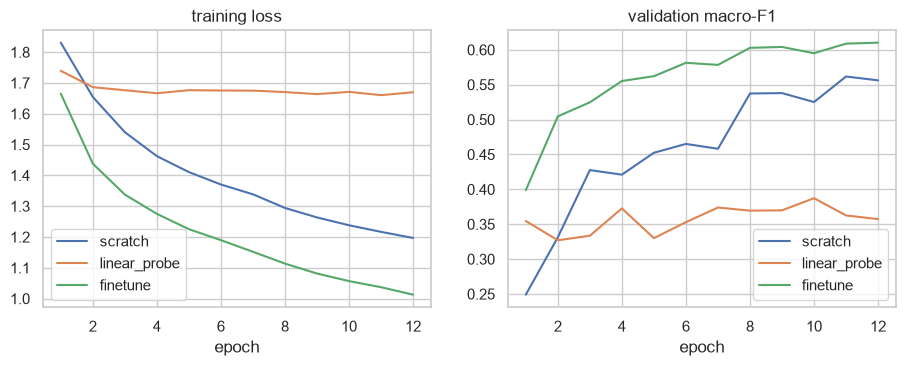

In [13]:
REG = {}
if C.RUN_STAGES["training_regime"]:
    regimes = (["scratch"] if CONFIG["initialization"]["scratch_experiments"]
               and "pretrained_vs_scratch" in ENABLED_COMPARISONS else [])
    if CONFIG["initialization"]["fine_tuning_experiments"]:
        regimes.extend(["linear_probe", "finetune"])
    for regime in regimes:
        REG[regime] = run_experiment(f"C_{regime}_{AB}", AB, replace(FINAL_RECIPE, regime=regime),
                                     FER_TRAIN, FER_VAL, stage="C", note=regime)
    have = {k: v for k, v in REG.items() if v}
    if have:
        display(runs_table([v["exp_id"] for v in have.values()]))
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
        for regime, r in have.items():
            h = pd.read_csv(OUT / "runs" / r["exp_id"] / "history.csv")
            axes[0].plot(h.epoch, h.train_loss, label=regime); axes[1].plot(h.epoch, h.val_macro_f1, label=regime)
        axes[0].set_title("training loss"); axes[1].set_title("validation macro-F1")
        for a in axes:
            a.set_xlabel("epoch"); a.legend()
        save_fig(fig, "stageC_regimes")

## Stage D — Architecture comparison under one shared recipe

Every architecture uses `FINAL_RECIPE` (learning rates scaled by family: CNN, transformer, or from-scratch) and the
same epochs, so differences reflect the architecture rather than the recipe. The two custom CNNs are trained from
scratch at 48 px, which isolates the effect of the CBAM attention modules the report never ablated.

[train] D_resnet50_s0: resnet50 | 23.5M params | 112px | pretrained=True | lr 0.0003/0.001 | n_train=26,911
   ep  1 loss 1.645 acc 0.395 | val acc 0.4976 mF1 0.4110 * | 844s
   ep  2 loss 1.388 acc 0.531 | val acc 0.5528 mF1 0.5095 * | 843s
   ep  3 loss 1.261 acc 0.596 | val acc 0.6007 mF1 0.5504 * | 846s
   ep  4 loss 1.179 acc 0.643 | val acc 0.6088 mF1 0.5750 * | 4500s
   ep  5 loss 1.120 acc 0.673 | val acc 0.6289 mF1 0.5880 * | 847s
   ep  6 loss 1.078 acc 0.697 | val acc 0.6191 mF1 0.5904 * | 859s
   ep  7 loss 1.022 acc 0.727 | val acc 0.6461 mF1 0.6242 * | 854s
   ep  8 loss 0.974 acc 0.749 | val acc 0.6461 mF1 0.6249 * | 849s
   ep  9 loss 0.936 acc 0.772 | val acc 0.6506 mF1 0.6302 * | 4506s
   ep 10 loss 0.901 acc 0.794 | val acc 0.6682 mF1 0.6480 * | 844s
   ep 11 loss 0.873 acc 0.803 | val acc 0.6604 mF1 0.6390 | 848s
   ep 12 loss 0.846 acc 0.820 | val acc 0.6559 mF1 0.6364 | 847s
   ep 13 loss 0.815 acc 0.835 | val acc 0.6581 mF1 0.6376 | 4497s
   ep 14 loss 0.795 acc 

,exp_id,stage,model,regime,labels,img,seed,val_acc,val_macro_f1,val_bal_acc,val_ece,best_ep,minutes,params_M,pretrained,collapsed,note
3,D_vit_small_patch16_224_s0,D,vit_small_patch16_224,finetune,fer2013,112,0,0.682920,0.659650,0.653453,0.036013,10,100.519757,21.611911,True,False,architecture
2,D_efficientnet_b0_s0,D,efficientnet_b0,finetune,fer2013,112,0,0.668989,0.652997,0.646931,0.069054,18,168.137803,4.016515,True,False,architecture
1,D_convnext_tiny_s0,D,convnext_tiny,finetune,fer2013,112,0,0.672611,0.652119,0.644099,0.090072,18,306.959199,27.825511,True,False,architecture
6,D_mobilenetv3_large_100_s0,D,mobilenetv3_large_100,finetune,fer2013,112,0,0.663973,0.650322,0.640987,0.077505,13,93.990643,4.210999,True,False,architecture
4,D_deit_tiny_patch16_224_s0,D,deit_tiny_patch16_224,finetune,fer2013,112,0,0.663137,0.649099,0.648825,0.066882,19,66.527245,5.497543,True,False,architecture
0,D_resnet50_s0,D,resnet50,finetune,fer2013,112,0,0.668153,0.647984,0.646622,0.030999,10,406.733622,23.522375,True,False,architecture
5,D_hybrid_cnn_transformer_s0,D,hybrid_cnn_transformer,finetune,fer2013,112,0,0.638061,0.612477,0.619196,0.058543,19,86.283726,3.918151,True,False,architecture
8,D_custom_cnn_noattn_s0,D,custom_cnn_noattn,scratch,fer2013,48,0,0.623572,0.597700,0.599767,0.078028,17,42.333888,1.241063,False,False,architecture
7,D_custom_attn_cnn_s0,D,custom_attn_cnn,scratch,fer2013,48,0,0.607412,0.558980,0.556387,0.038966,12,55.037969,1.263368,False,False,architecture


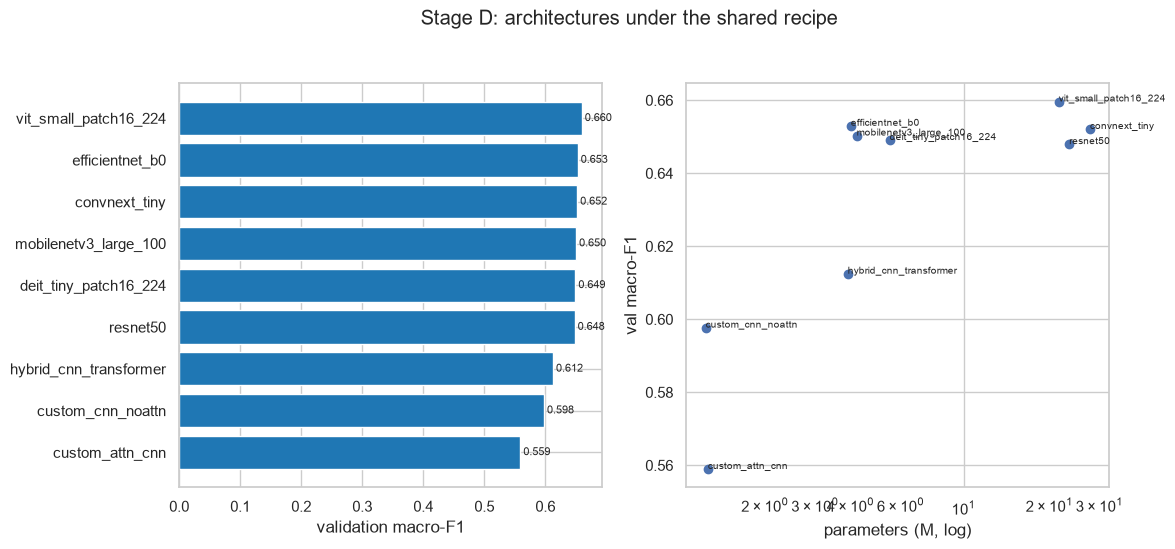

CBAM attention ablation (custom CNN, scratch): attention changes val macro-F1 by -0.0387


In [14]:
ARCH = {}
if C.RUN_STAGES["architecture_search"]:
    arch_list = [m for m in P["arch_candidates"] if m in CONFIG["models"]["enabled_architectures"]]
    if "custom_attn_cnn" in arch_list and "custom_cnn_noattn" not in arch_list:
        arch_list.append("custom_cnn_noattn")
    if "hsemotion_enet_b0" in MODEL_SPECS:
        arch_list.append("hsemotion_enet_b0")
    for m_ in arch_list:
        rc = replace(FINAL_RECIPE, epochs=P["epochs_arch"])
        if MODEL_SPECS[m_]["family"] == "scratch":
            rc = replace(rc, regime="scratch", img_size=48, drop_path=0.0)
        ARCH[m_] = run_experiment(f"D_{m_}_s0", m_, rc, FER_TRAIN, FER_VAL, stage="D", note="architecture")
    tD = runs_table([r["exp_id"] for r in ARCH.values() if r]).sort_values("val_macro_f1", ascending=False)
    display(tD)
    tD.to_csv(OUT / "tables" / "stageD_architectures.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * len(tD) + 1.2))
    axes[0].barh(tD["model"], tD["val_macro_f1"], color="#1f77b4")
    axes[0].invert_yaxis(); axes[0].set_xlabel("validation macro-F1")
    for y_, v_ in enumerate(tD["val_macro_f1"]):
        axes[0].text(v_, y_, f" {v_:.3f}", va="center", fontsize=8)
    axes[1].scatter(tD["params_M"], tD["val_macro_f1"])
    for _, r_ in tD.iterrows():
        axes[1].annotate(r_["model"], (r_["params_M"], r_["val_macro_f1"]), fontsize=7)
    axes[1].set_xscale("log"); axes[1].set_xlabel("parameters (M, log)"); axes[1].set_ylabel("val macro-F1")
    fig.suptitle("Stage D: architectures under the shared recipe", y=1.02)
    save_fig(fig, "stageD_architectures")
    if ARCH.get("custom_attn_cnn") and ARCH.get("custom_cnn_noattn"):
        d_att = vf1(ARCH["custom_attn_cnn"]) - vf1(ARCH["custom_cnn_noattn"])
        print(f"CBAM attention ablation (custom CNN, scratch): attention changes val macro-F1 by {d_att:+.4f}")

## Stage E — Label source: original FER2013 labels vs FER+ crowd vote distributions

The best Stage-D architecture is retrained on FER+ soft labels (10 annotators per image). Both runs are scored on
the **same validation set with the original FER2013 labels** (the benchmark labels) and, for information, against the
FER+ majority labels.

In [15]:
LABELS = {}
if C.RUN_STAGES["label_source"] and HAS_FERPLUS and ARCH:
    healthy = [r for r in ARCH.values() if r and not r["collapsed"]] or [r for r in ARCH.values() if r]
    best_arch = max(healthy, key=vf1)
    rc = replace(Recipe(**best_arch["recipe"]), label_source="ferplus_soft")
    LABELS["fer2013"] = best_arch
    LABELS["ferplus_soft"] = run_experiment(f"E_{best_arch['model']}_ferplus_s0", best_arch["model"], rc,
                                            FER_TRAIN, FER_VAL, stage="E", note="FER+ soft labels")
    vmask = META.set_index("gidx").loc[FER_VAL, "ferplus_valid"].to_numpy()
    yfp = META.set_index("gidx").loc[FER_VAL, "ferplus_label"].to_numpy()
    rows = []
    for src, r in LABELS.items():
        if r is None:
            continue
        rows.append({"trained on": src, "val macro-F1 (FER2013 labels)": vf1(r),
                     "val acc (FER2013 labels)": r["val"]["acc"],
                     "val macro-F1 (FER+ majority)": compute_metrics(yfp[vmask], r["val_probs"][vmask])["macro_f1"]})
    display(pd.DataFrame(rows))
elif C.RUN_STAGES["label_source"]:
    print("Stage E skipped: needs FERPLUS_CSV together with FER2013_CSV.")

Stage E skipped: needs FERPLUS_CSV together with FER2013_CSV.


## Stage F — Retrain the finalists with several seeds

The top `top_k_multiseed` configurations by validation macro-F1 (Stages D and E, plus the baselines for a fair
comparison) are retrained with every seed in `seeds_final`. Selection in § H uses the **mean** over seeds, so a lucky
seed cannot win.

In [16]:
def cand_key(r):
    """Configuration identity ignoring seed and epoch budget."""
    rc = {k: v for k, v in r["recipe"].items() if k not in ("epochs", "patience")}
    sig = hashlib.md5(json.dumps(rc, sort_keys=True).encode()).hexdigest()[:6]
    return f"{r['model']}|{rc['label_source']}|{rc['regime']}|{rc['img_size']}px|{sig}"

BASELINE_KEYS = set()

CANDIDATES = {}   # key -> list of exp_ids
ALL_COLLAPSED = False
def _add(r):
    if r and (ALL_COLLAPSED or not r["collapsed"]):
        CANDIDATES.setdefault(cand_key(r), [])
        if r["exp_id"] not in CANDIDATES[cand_key(r)]:
            CANDIDATES[cand_key(r)].append(r["exp_id"])

pool = [r for r in list(ARCH.values()) + list(LABELS.values()) if r]
if not pool:   # architecture stage disabled: fall back to whatever has been trained
    pool = [r for r in RUNS.values() if r and r["stage"] in ("B", "C")]
ALL_COLLAPSED = bool(pool) and all(r["collapsed"] for r in pool)
if ALL_COLLAPSED:
    print("WARNING: every candidate run is flagged as collapsed (one-class or near-chance predictions). "
          "Continuing so the pipeline completes, but these results are not meaningful: check learning rates, "
          "pretrained weights and the data before trusting anything below.")
for r in pool:
    _add(r)
if C.RUN_STAGES["multiseed_finalists"] and pool:
    ranked = sorted({cand_key(r): r for r in pool if ALL_COLLAPSED or not r["collapsed"]}.values(), key=vf1, reverse=True)
    finalists = ranked[:P["top_k_multiseed"]]
    print("Finalists:", [cand_key(r) for r in finalists])
    for r in finalists:
        rc = replace(Recipe(**r["recipe"]), epochs=P["epochs_final"])
        for sd in P["seeds_final"]:
            res = run_experiment(f"F_{r['model']}_{rc.label_source}_s{sd}", r["model"], rc, FER_TRAIN, FER_VAL,
                                 seed=sd, stage="F", note="finalist")
            if res and (ALL_COLLAPSED or not res["collapsed"]):
                CANDIDATES.setdefault(cand_key(r), [])
                if res["exp_id"] not in CANDIDATES[cand_key(r)]:
                    CANDIDATES[cand_key(r)].append(res["exp_id"])
    # baselines get the same seeds, so the final baseline comparison is seed-matched
    if A1 and len(P["seeds_final"]) > 1:
        for sd in P["seeds_final"]:
            res = run_experiment(f"F_baseline_A1_s{sd}", "tv_resnet50", REPORT_RECIPE, FER_TRAIN, FER_VAL,
                                 seed=sd, stage="F", note="baseline seeds")
for bid in ["A1_report_resnet50", "A2_report_custom_cnn"] + [f"F_baseline_A1_s{sd}" for sd in P["seeds_final"]]:
    if RUNS.get(bid):
        _add(RUNS[bid])
        BASELINE_KEYS.add(cand_key(RUNS[bid]))

Finalists: ['vit_small_patch16_224|fer2013|finetune|112px|4ea01c']
[reuse] F_vit_small_patch16_224_fer2013_s0 = D_vit_small_patch16_224_s0 (identical configuration)


## Stage G — Ensemble of the finalists
The best-seed checkpoint of each finalist configuration (different architectures) is combined by averaging
probabilities. The ensemble is a candidate like any other and must win on validation to be selected.

In [17]:
def get_probs(exp_id, split_name, idx):
    """Probabilities with the global TTA setting; cached per run and split."""
    f = OUT / "runs" / RUNS[exp_id]["exp_id"] / f"{split_name}_probs{'_tta' if USE_TTA else ''}.npy"
    if split_name == "val" and not USE_TTA and len(idx) == len(RUNS[exp_id]["val_probs"]):
        return RUNS[exp_id]["val_probs"]
    if f.exists():
        p = np.load(f)
        if len(p) == len(idx):
            return p
    p = predict_split(exp_id, idx, split_name, tta=USE_TTA)
    np.save(f, p.astype(np.float32))
    return p

def best_seed(key):
    return max(CANDIDATES[key], key=lambda e: get_probs_val_f1(e))

def get_probs_val_f1(e):
    return compute_metrics(Y_ALL[FER_VAL], get_probs(e, "val", FER_VAL))["macro_f1"]

ENSEMBLE = None
non_baseline = [k for k in CANDIDATES if k not in BASELINE_KEYS]
if C.RUN_STAGES["ensemble"] and len(non_baseline) >= 2:
    ranked_keys = sorted(non_baseline, key=lambda k: np.mean([get_probs_val_f1(e) for e in CANDIDATES[k]]), reverse=True)
    members = [best_seed(k) for k in ranked_keys[:max(2, P["top_k_multiseed"])]]
    ens_val = np.mean([get_probs(e, "val", FER_VAL) for e in members], 0)
    ENSEMBLE = {"members": members, "val": compute_metrics(Y_ALL[FER_VAL], ens_val)}
    print(f"Ensemble of {members}: val macro-F1 {ENSEMBLE['val']['macro_f1']:.4f}, acc {ENSEMBLE['val']['acc']:.4f}")

Ensemble of ['D_vit_small_patch16_224_s0', 'D_deit_tiny_patch16_224_s0']: val macro-F1 0.6749, acc 0.6927


## H. Final selection on validation — then, and only then, the test set

Candidates are ranked by **mean validation macro-F1 across seeds**. The winner and its deployable checkpoint
(best seed) are written to `selection.json` **before** any test prediction is made; `predict_split` refuses test data
until this lock exists.

In [18]:
cand_rows = []
for key, ids in CANDIDATES.items():
    f1s = [get_probs_val_f1(e) for e in ids]
    accs = [compute_metrics(Y_ALL[FER_VAL], get_probs(e, "val", FER_VAL))["acc"] for e in ids]
    cand_rows.append({"candidate": key + (" (baseline)" if key in BASELINE_KEYS else ""), "type": "single", "n_seeds": len(ids), "val_macro_f1_mean": np.mean(f1s),
                      "val_macro_f1_std": np.std(f1s), "val_acc_mean": np.mean(accs), "runs": ids,
                      "deployable": max(ids, key=get_probs_val_f1)})
if ENSEMBLE:
    cand_rows.append({"candidate": "ensemble(" + ", ".join(RUNS[e]["model"] for e in ENSEMBLE["members"]) + ")",
                      "type": "ensemble", "n_seeds": 1, "val_macro_f1_mean": ENSEMBLE["val"]["macro_f1"],
                      "val_macro_f1_std": 0.0, "val_acc_mean": ENSEMBLE["val"]["acc"], "runs": ENSEMBLE["members"],
                      "deployable": ENSEMBLE["members"][0]})
CAND = pd.DataFrame(cand_rows).sort_values("val_macro_f1_mean", ascending=False).reset_index(drop=True)
if CAND.empty:
    raise RuntimeError("No trained candidate is available — check the messages above (skipped runs, missing weights).")
display(CAND[["candidate", "type", "n_seeds", "val_macro_f1_mean", "val_macro_f1_std", "val_acc_mean", "deployable"]])
CAND.drop(columns=["runs"]).to_csv(OUT / "tables" / "selection_candidates.csv", index=False)

winner = CAND.iloc[0]
SELECTION = {"candidate": winner["candidate"], "type": winner["type"], "runs": list(winner["runs"]),
             "deployable": winner["deployable"], "val_macro_f1_mean": float(winner["val_macro_f1_mean"]),
             "val_macro_f1_std": float(winner["val_macro_f1_std"]), "tta": USE_TTA,
             "baseline": BASELINE_ID, "locked_at": time.strftime("%Y-%m-%d %H:%M:%S"),
             "deployable_sha256": RUNS[winner["deployable"]]["ckpt_sha256"]}
_ = (OUT / "selection.json").write_text(json.dumps(SELECTION, indent=1))
print("SELECTION LOCKED:", json.dumps(SELECTION, indent=1))

,candidate,type,n_seeds,val_macro_f1_mean,val_macro_f1_std,val_acc_mean,deployable
0,"ensemble(vit_small_patch16_224, deit_tiny_patch16_224)",ensemble,1,0.674945,0.0,0.692672,D_vit_small_patch16_224_s0
1,vit_small_patch16_224|fer2013|finetune|112px|4ea01c,single,1,0.659192,0.0,0.687935,D_vit_small_patch16_224_s0
2,deit_tiny_patch16_224|fer2013|finetune|112px|4ea01c,single,1,0.655049,0.0,0.667038,D_deit_tiny_patch16_224_s0
3,resnet50|fer2013|finetune|112px|4ea01c,single,1,0.653062,0.0,0.674283,D_resnet50_s0
4,mobilenetv3_large_100|fer2013|finetune|112px|4ea01c,single,1,0.651868,0.0,0.663695,D_mobilenetv3_large_100_s0
5,efficientnet_b0|fer2013|finetune|112px|4ea01c,single,1,0.650720,0.0,0.667595,D_efficientnet_b0_s0
6,tv_resnet50|fer2013|finetune|224px|e4b94d (baseline),single,1,0.648994,0.0,0.673725,A1_report_resnet50
7,convnext_tiny|fer2013|finetune|112px|4ea01c,single,1,0.648435,0.0,0.667317,D_convnext_tiny_s0
8,hybrid_cnn_transformer|fer2013|finetune|112px|4ea01c,single,1,0.625953,0.0,0.654778,D_hybrid_cnn_transformer_s0
9,custom_cnn_noattn|fer2013|scratch|48px|5006ef,single,1,0.604604,0.0,0.628587,D_custom_cnn_noattn_s0


SELECTION LOCKED: {
 "candidate": "ensemble(vit_small_patch16_224, deit_tiny_patch16_224)",
 "type": "ensemble",
 "runs": [
  "D_vit_small_patch16_224_s0",
  "D_deit_tiny_patch16_224_s0"
 ],
 "deployable": "D_vit_small_patch16_224_s0",
 "val_macro_f1_mean": 0.6749449398675482,
 "val_macro_f1_std": 0.0,
 "tta": true,
 "baseline": "A1_report_resnet50",
 "locked_at": "2026-10-23 11:55:25",
 "deployable_sha256": "52dc47e4418ec4874b5dbef5562e2cfc01c79954c829aea2e845594fe9ec66d3"
}


### H.1 Test-set results (opened once, after the lock)
All candidates are scored for transparency, but only the locked selection is the reported result. For multi-seed
candidates the mean ± standard deviation over seeds is the honest estimate; the deployable checkpoint is reported too.

In [19]:
Y_TEST = Y_ALL[FER_TEST]
def test_metrics(ids):
    probs = np.mean([get_probs(e, "test", FER_TEST) for e in ids], 0)
    return compute_metrics(Y_TEST, probs), probs

test_rows = []
for _, c in CAND.iterrows():
    if c["type"] == "ensemble":
        m, _ = test_metrics(c["runs"])
        accs, f1s = [m["acc"]], [m["macro_f1"]]
    else:
        ms = [compute_metrics(Y_TEST, get_probs(e, "test", FER_TEST)) for e in c["runs"]]
        accs, f1s = [m["acc"] for m in ms], [m["macro_f1"] for m in ms]
    test_rows.append({"candidate": c["candidate"], "selected": c["candidate"] == SELECTION["candidate"],
                      "n_seeds": c["n_seeds"], "val_macro_f1": c["val_macro_f1_mean"],
                      "test_acc_mean": np.mean(accs), "test_acc_std": np.std(accs),
                      "test_macro_f1_mean": np.mean(f1s), "test_macro_f1_std": np.std(f1s)})
TEST_TABLE = pd.DataFrame(test_rows)
display(TEST_TABLE)
TEST_TABLE.to_csv(OUT / "tables" / "test_results_all_candidates.csv", index=False)

SEL_MEMBERS = SELECTION["runs"] if SELECTION["type"] == "ensemble" else [SELECTION["deployable"]]

def sel_predict(idx, split_name, perturb=None):
    """Probabilities of the selected model (averaged over members if it is an ensemble)."""
    return np.mean([predict_split(e, idx, split_name, tta=USE_TTA, perturb=perturb) for e in SEL_MEMBERS], 0)

SEL_PROBS = np.mean([get_probs(e, "test", FER_TEST) for e in SEL_MEMBERS], 0)
SEL_TEST = compute_metrics(Y_TEST, SEL_PROBS)
print(f"Selected ({SELECTION['candidate']}), deployable checkpoint {SELECTION['deployable']}: "
      f"test acc {SEL_TEST['acc']:.4f}, macro-F1 {SEL_TEST['macro_f1']:.4f}")
BASE_PROBS = get_probs(BASELINE_ID, "test", FER_TEST) if BASELINE_ID else None
BASE_TEST = compute_metrics(Y_TEST, BASE_PROBS) if BASELINE_ID else None

def mcnemar(y, p1, p2):
    a, b = (p1 == y), (p2 == y)
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    if n01 + n10 == 0:
        return n01, n10, 1.0
    if n01 + n10 < 25:
        return n01, n10, float(stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue)
    chi = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
    return n01, n10, float(1 - stats.chi2.cdf(chi, 1))

def bootstrap_diff(y, p_new, p_old, rounds=C.BOOTSTRAP_ROUNDS, seed=0):
    rng = np.random.default_rng(seed)
    d_f1, d_acc = [], []
    for _ in range(rounds):
        i = rng.integers(0, len(y), len(y))
        d_f1.append(f1_score(y[i], p_new[i], average="macro", labels=range(K), zero_division=0) -
                    f1_score(y[i], p_old[i], average="macro", labels=range(K), zero_division=0))
        d_acc.append((p_new[i] == y[i]).mean() - (p_old[i] == y[i]).mean())
    return np.percentile(d_f1, [2.5, 97.5]), np.percentile(d_acc, [2.5, 97.5])

COMPARISON = None
if BASE_TEST is not None:
    n01, n10, p_mc = mcnemar(Y_TEST, SEL_TEST["pred"], BASE_TEST["pred"])
    ci_f1, ci_acc = bootstrap_diff(Y_TEST, SEL_TEST["pred"], BASE_TEST["pred"])
    COMPARISON = {"baseline_acc": BASE_TEST["acc"], "baseline_macro_f1": BASE_TEST["macro_f1"],
                  "selected_acc": SEL_TEST["acc"], "selected_macro_f1": SEL_TEST["macro_f1"],
                  "delta_acc": SEL_TEST["acc"] - BASE_TEST["acc"], "delta_macro_f1": SEL_TEST["macro_f1"] - BASE_TEST["macro_f1"],
                  "ci95_delta_macro_f1": ci_f1.tolist(), "ci95_delta_acc": ci_acc.tolist(),
                  "mcnemar_selected_only_correct": n01, "mcnemar_baseline_only_correct": n10, "mcnemar_p": p_mc}
    (OUT / "tables" / "baseline_vs_selected.json").write_text(json.dumps(COMPARISON, indent=1))
    display(pd.Series(COMPARISON, name="baseline (A1) vs selected, FER2013 test").to_frame())

pc = pd.DataFrame({"baseline F1": {c: BASE_TEST["per_class"][c]["f1"] for c in CLASSES} if BASE_TEST else {},
                   "selected F1": {c: SEL_TEST["per_class"][c]["f1"] for c in CLASSES},
                   "selected precision": {c: SEL_TEST["per_class"][c]["precision"] for c in CLASSES},
                   "selected recall": {c: SEL_TEST["per_class"][c]["recall"] for c in CLASSES},
                   "support": {c: SEL_TEST["per_class"][c]["support"] for c in CLASSES}})
display(pc)
pc.to_csv(OUT / "tables" / "per_class_test.csv")
if HAS_FERPLUS:
    tm = META.set_index("gidx").loc[FER_TEST]
    ok = tm["ferplus_valid"].to_numpy()
    print(f"Selected model vs FER+ majority labels on test: macro-F1 "
          f"{compute_metrics(tm['ferplus_label'].to_numpy()[ok], SEL_PROBS[ok])['macro_f1']:.4f}")

,candidate,selected,n_seeds,val_macro_f1,test_acc_mean,test_acc_std,test_macro_f1_mean,test_macro_f1_std
0,"ensemble(vit_small_patch16_224, deit_tiny_patch16_224)",True,1,0.674945,0.704932,0.0,0.695648,0.0
1,vit_small_patch16_224|fer2013|finetune|112px|4ea01c,False,1,0.659192,0.685149,0.0,0.675272,0.0
2,deit_tiny_patch16_224|fer2013|finetune|112px|4ea01c,False,1,0.655049,0.670103,0.0,0.651502,0.0
3,resnet50|fer2013|finetune|112px|4ea01c,False,1,0.653062,0.678462,0.0,0.657615,0.0
4,mobilenetv3_large_100|fer2013|finetune|112px|4ea01c,False,1,0.651868,0.675676,0.0,0.660460,0.0
5,efficientnet_b0|fer2013|finetune|112px|4ea01c,False,1,0.650720,0.683199,0.0,0.672311,0.0
6,tv_resnet50|fer2013|finetune|224px|e4b94d (baseline),False,1,0.648994,0.686821,0.0,0.663526,0.0
7,convnext_tiny|fer2013|finetune|112px|4ea01c,False,1,0.648435,0.667317,0.0,0.658076,0.0
8,hybrid_cnn_transformer|fer2013|finetune|112px|4ea01c,False,1,0.625953,0.671496,0.0,0.648229,0.0
9,custom_cnn_noattn|fer2013|scratch|48px|5006ef,False,1,0.604604,0.638618,0.0,0.627357,0.0


Selected (ensemble(vit_small_patch16_224, deit_tiny_patch16_224)), deployable checkpoint D_vit_small_patch16_224_s0: test acc 0.7049, macro-F1 0.6956


,"baseline (A1) vs selected, FER2013 test"
baseline_acc,0.686821
baseline_macro_f1,0.663526
selected_acc,0.704932
selected_macro_f1,0.695648
delta_acc,0.018111
delta_macro_f1,0.032121
ci95_delta_macro_f1,"[0.011478195836912375, 0.052684979410207534]"
ci95_delta_acc,"[0.0039008080245194173, 0.03176372248537196]"
mcnemar_selected_only_correct,358
mcnemar_baseline_only_correct,293


,baseline F1,selected F1,selected precision,selected recall,support
angry,0.599782,0.623701,0.636943,0.610998,491
disgust,0.609524,0.720000,0.800000,0.654545,55
fear,0.512146,0.557282,0.571713,0.543561,528
happy,0.888364,0.896552,0.921875,0.872582,879
sad,0.579623,0.564103,0.538226,0.592593,594
surprise,0.776675,0.813926,0.812950,0.814904,416
neutral,0.678571,0.693972,0.672156,0.717252,626


## Stage I — Cross-dataset generalisation

**I.1 Zero-shot:** the selected FER2013 model is applied, unchanged, to the subject-independent test split of each
external dataset. Two scorings are shown:
* *open* — the model chooses among all 7 classes (a CREMA-D face predicted as "surprise" counts as wrong);
* *closed* — the argmax is restricted to the classes that exist in that dataset.

For video datasets, frame probabilities are also averaged per clip (video-level), as in the report.

**I.2 Multi-dataset training:** the same architecture and recipe are trained on FER2013 train **plus** the
subject-independent train splits of the external datasets (validation: the union of the validation splits), then
scored on every test split. Comparing I.1 and I.2 shows whether seeing other recording conditions improves
generalisation and what it costs on FER2013.

[train] I_multidataset_vit_small_patch16_224: vit_small_patch16_224 | 21.6M params | 112px | pretrained=True | lr 0.0001/0.001 | n_train=48,863
   ep  1 loss 1.408 acc 0.528 | val acc 0.5420 mF1 0.5200 * | 710s
   ep  2 loss 1.127 acc 0.676 | val acc 0.5577 mF1 0.5388 * | 656s
   ep  3 loss 1.032 acc 0.720 | val acc 0.5700 mF1 0.5484 * | 757s
   ep  4 loss 0.976 acc 0.749 | val acc 0.5777 mF1 0.5519 * | 654s
   ep  5 loss 0.930 acc 0.771 | val acc 0.5671 mF1 0.5466 | 640s
   ep  6 loss 0.903 acc 0.784 | val acc 0.5764 mF1 0.5485 | 579s
   ep  7 loss 0.870 acc 0.799 | val acc 0.5909 mF1 0.5766 * | 576s
   ep  8 loss 0.843 acc 0.814 | val acc 0.5837 mF1 0.5575 | 585s
   ep  9 loss 0.816 acc 0.826 | val acc 0.5926 mF1 0.5663 | 568s
   ep 10 loss 0.795 acc 0.839 | val acc 0.5839 mF1 0.5641 | 582s
   ep 11 loss 0.779 acc 0.848 | val acc 0.5863 mF1 0.5639 | 608s
   ep 12 loss 0.763 acc 0.855 | val acc 0.5833 mF1 0.5631 | 599s
   ep 13 loss 0.742 acc 0.864 | val acc 0.5960 mF1 0.5715 | 621s
 

frames  subjects  classes  frame acc (open)  frame macro-F1 (open)  frame acc (closed)  frame macro-F1 (closed)  video acc (open)  video macro-F1 (open)  \
dataset training                                                                                                                                                                             
FER2013 FER2013 + external (I.2)    3589         0        7            0.6740                 0.6494              0.6740                   0.6494               NaN                    NaN   
        FER2013 only (selected)     3589         0        7            0.7049                 0.6956              0.7049                   0.6956               NaN                    NaN   
RAVDESS FER2013 + external (I.2)    5632         4        7            0.5435                 0.4856              0.5435                   0.4856            0.5781                 0.5141   
        FER2013 only (selected)     5632         4        7            0.3226                 0.2808              0.3226                   0.2808            0.3267                 0.2680   

                                  video acc (closed)  video macro-F1 (closed)  
dataset training                                                               
FER2013 FER2013 + external (I.2)                 NaN                      NaN  
        FER2013 only (selected)                  NaN                      NaN  
RAVDESS FER2013 + external (I.2)              0.5781                   0.5141  
        FER2013 only (selected)               0.3267                   0.2680

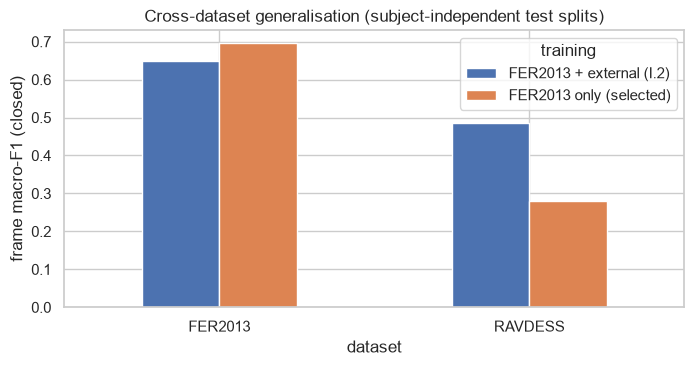

In [20]:
def score_dataset(probs, name, idx):
    m = META.set_index("gidx").loc[idx]
    y = m["label"].to_numpy()
    present = sorted(np.unique(y).tolist())
    out = {"dataset": name, "frames": len(idx), "subjects": m["subject"].nunique(),
           "classes": len(present)}
    for mode, restrict in [("open", False), ("closed", True)]:
        r = compute_metrics(y, probs, labels=present, restrict=restrict)
        out[f"frame acc ({mode})"], out[f"frame macro-F1 ({mode})"] = r["acc"], r["macro_f1"]
    vids = m["video_id"].to_numpy()
    if pd.notna(vids).all() and name != "FER2013" and len(np.unique(vids)) < len(vids):
        dfp = pd.DataFrame(probs, index=vids).groupby(level=0).mean()
        yv = pd.Series(y, index=vids).groupby(level=0).first().loc[dfp.index].to_numpy()
        for mode, restrict in [("open", False), ("closed", True)]:
            r = compute_metrics(yv, dfp.to_numpy(), labels=present, restrict=restrict)
            out[f"video acc ({mode})"], out[f"video macro-F1 ({mode})"] = r["acc"], r["macro_f1"]
    return out

CROSS = None
if C.RUN_STAGES["cross_dataset"] and EXTERNAL:
    rows = [score_dataset(SEL_PROBS, "FER2013", FER_TEST) | {"training": "FER2013 only (selected)"}]
    for name in EXTERNAL:
        idx = gidx(name, "test")
        if len(idx):
            rows.append(score_dataset(sel_predict(idx, "test"), name, idx) | {"training": "FER2013 only (selected)"})

    ext_train = np.concatenate([gidx(n, "train") for n in EXTERNAL])
    ext_val = np.concatenate([gidx(n, "val") for n in EXTERNAL])
    if len(ext_train) and len(ext_val):
        base_run = RUNS[SELECTION["deployable"]]
        rc = replace(Recipe(**base_run["recipe"]), epochs=P["epochs_final"], label_source="fer2013")
        multi = run_experiment(f"I_multidataset_{base_run['model']}", base_run["model"], rc,
                               np.concatenate([FER_TRAIN, ext_train]), np.concatenate([FER_VAL, ext_val]),
                               stage="I", note="FER2013 + external train splits")
        if multi:
            for name in ["FER2013"] + EXTERNAL:
                idx = FER_TEST if name == "FER2013" else gidx(name, "test")
                if len(idx):
                    p_ = predict_split(multi["exp_id"], idx, "test", tta=USE_TTA)
                    rows.append(score_dataset(p_, name, idx) | {"training": "FER2013 + external (I.2)"})
    CROSS = pd.DataFrame(rows).set_index(["dataset", "training"]).sort_index()
    display(CROSS.round(4))
    CROSS.to_csv(OUT / "tables" / "cross_dataset.csv")
    col = "frame macro-F1 (closed)"
    piv = CROSS[col].unstack("training")
    ax = piv.plot.bar(figsize=(8, 3.6), rot=0)
    ax.set_ylabel(col); ax.set_title("Cross-dataset generalisation (subject-independent test splits)")
    save_fig(ax.figure, "stageI_cross_dataset")
elif C.RUN_STAGES["cross_dataset"]:
    print("Stage I skipped: no external dataset (CK+, RAVDESS, CREMA-D) configured.")

## Stage J — Error analysis of the selected model (FER2013 test)
Normalised confusion matrices (baseline vs selected), per-class F1 change, the most frequent confusions, the most
confident mistakes, a reliability diagram (calibration) and Grad-CAM heat-maps showing where the model looks.

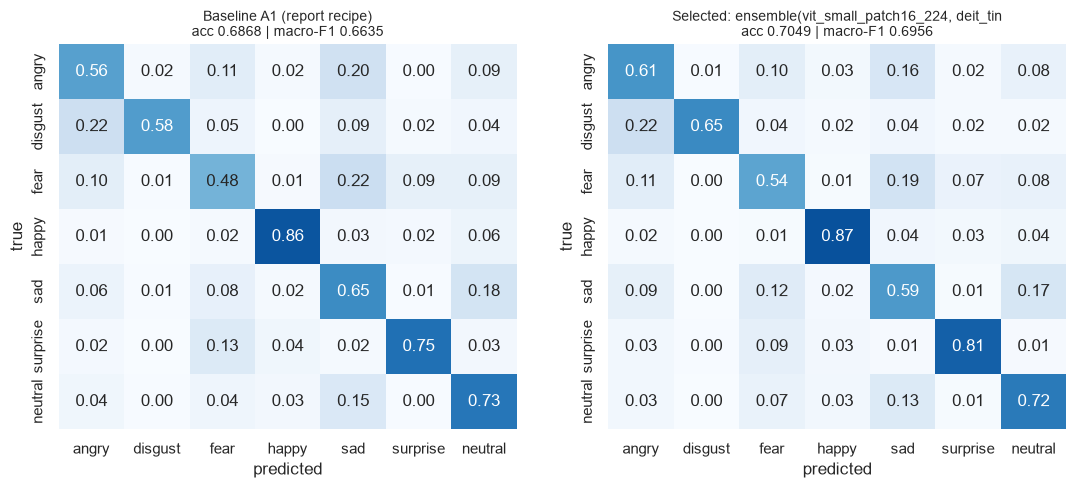

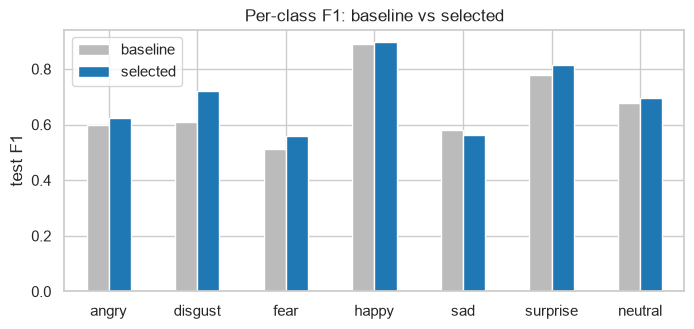

,true,predicted,count,share of true class
15,fear,sad,100,0.189394
29,sad,neutral,99,0.166667
40,neutral,sad,84,0.134185
3,angry,sad,79,0.160896
26,sad,fear,72,0.121212
12,fear,angry,58,0.109848
24,sad,angry,52,0.087542
1,angry,fear,50,0.101833


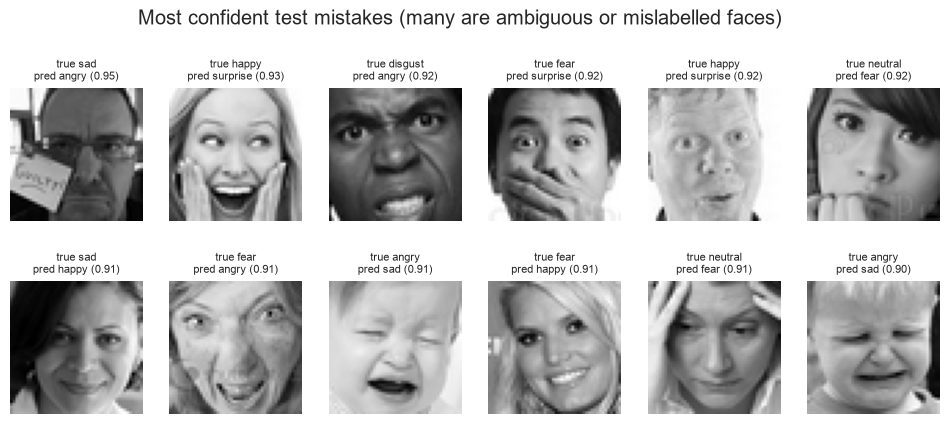

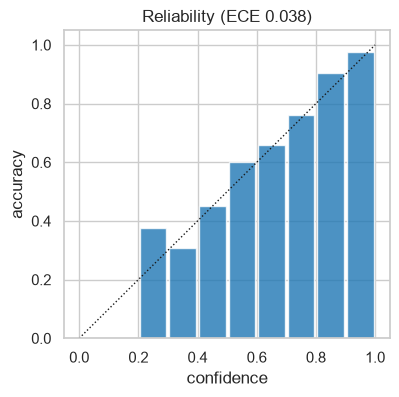

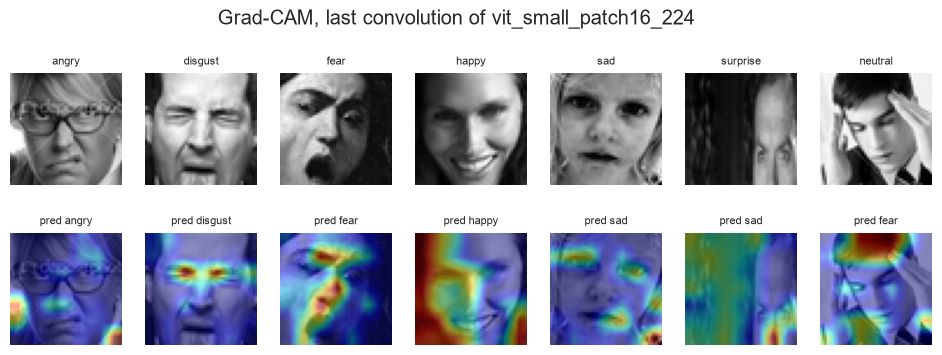

In [21]:
fig, axes = plt.subplots(1, 2 if BASE_TEST else 1, figsize=(13 if BASE_TEST else 6.5, 5), squeeze=False)
for ax, (title, met) in zip(axes[0], ([("Baseline A1 (report recipe)", BASE_TEST)] if BASE_TEST else []) +
                                    [("Selected: " + SELECTION["candidate"][:40], SEL_TEST)]):
    cm = np.array(met["cm"], float)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                cbar=False, vmin=0, vmax=1)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{title}\nacc {met['acc']:.4f} | macro-F1 {met['macro_f1']:.4f}", fontsize=10)
save_fig(fig, "stageJ_confusion_matrices")
pd.DataFrame(SEL_TEST["cm"], index=CLASSES, columns=CLASSES).to_csv(OUT / "tables" / "confusion_matrix_selected_test.csv")

if BASE_TEST:
    d = pd.DataFrame({"baseline": [BASE_TEST["per_class"][c]["f1"] for c in CLASSES],
                      "selected": [SEL_TEST["per_class"][c]["f1"] for c in CLASSES]}, index=CLASSES)
    ax = d.plot.bar(figsize=(8, 3.4), rot=0, color=["#bbbbbb", "#1f77b4"])
    ax.set_ylabel("test F1"); ax.set_title("Per-class F1: baseline vs selected")
    save_fig(ax.figure, "stageJ_per_class_f1")

cm = np.array(SEL_TEST["cm"])
pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j]), cm[i, j] / max(cm[i].sum(), 1))
         for i in range(K) for j in range(K) if i != j]
TOP_CONF = pd.DataFrame(pairs, columns=["true", "predicted", "count", "share of true class"]).sort_values(
    "count", ascending=False).head(8)
display(TOP_CONF)

# most confident mistakes
pred = SEL_PROBS.argmax(1)
wrong = np.where(pred != Y_TEST)[0]
top_wrong = wrong[np.argsort(-SEL_PROBS[wrong].max(1))][:12]
if len(top_wrong):
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
    for ax, i in zip(axes.ravel(), top_wrong):
        ax.imshow(IMAGES[FER_TEST[i]], cmap="gray"); ax.axis("off")
        ax.set_title(f"true {CLASSES[Y_TEST[i]]}\npred {CLASSES[pred[i]]} ({SEL_PROBS[i].max():.2f})", fontsize=8)
    for ax in axes.ravel()[len(top_wrong):]:
        ax.axis("off")
    fig.suptitle("Most confident test mistakes (many are ambiguous or mislabelled faces)", y=1.02)
    save_fig(fig, "stageJ_confident_errors")

# reliability diagram
conf, corr = SEL_PROBS.max(1), (pred == Y_TEST)
edges = np.linspace(0, 1, 11)
bins = np.clip(np.digitize(conf, edges) - 1, 0, 9)
acc_b = [corr[bins == b].mean() if (bins == b).any() else np.nan for b in range(10)]
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.bar((edges[:-1] + edges[1:]) / 2, acc_b, width=0.09, color="#1f77b4", alpha=0.8)
ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
ax.set_title(f"Reliability (ECE {SEL_TEST['ece']:.3f})")
save_fig(fig, "stageJ_reliability")

# Grad-CAM on the deployable checkpoint
def gradcam(model, idx, size):
    convs = [m for m in model.backbone.modules() if isinstance(m, nn.Conv2d)]
    if not convs:
        return None
    layer, store = convs[-1], {}
    h1 = layer.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: store.__setitem__("g", go[0]))
    model.eval()
    x = resample(fetch(idx), size).requires_grad_(True)
    logits = model(x)
    logits.gather(1, logits.argmax(1, keepdim=True)).sum().backward()
    h1.remove(); h2.remove()
    a, g = store["a"], store["g"]
    if a.dim() != 4:
        return None
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(S, S), mode="bilinear", align_corners=False)[:, 0]
    cam = cam / cam.flatten(1).amax(1).clamp_min(1e-8).view(-1, 1, 1)
    return cam.detach().cpu().numpy(), logits.argmax(1).cpu().numpy()

dep = load_model(SELECTION["deployable"])
show = np.concatenate([np.where(Y_TEST == c)[0][:1] for c in range(K)])
gc = gradcam(dep, FER_TEST[show], dep.fixed_size or RUNS[SELECTION["deployable"]]["recipe"]["img_size"])
if gc is not None:
    cams, gp = gc
    fig, axes = plt.subplots(2, len(show), figsize=(1.7 * len(show), 3.8))
    for j, i in enumerate(show):
        axes[0, j].imshow(IMAGES[FER_TEST[i]], cmap="gray"); axes[0, j].axis("off")
        axes[0, j].set_title(CLASSES[Y_TEST[i]], fontsize=8)
        axes[1, j].imshow(IMAGES[FER_TEST[i]], cmap="gray"); axes[1, j].imshow(cams[j], cmap="jet", alpha=0.45)
        axes[1, j].axis("off"); axes[1, j].set_title(f"pred {CLASSES[gp[j]]}", fontsize=8)
    fig.suptitle(f"Grad-CAM, last convolution of {RUNS[SELECTION['deployable']]['model']}", y=1.02)
    save_fig(fig, "stageJ_gradcam")
del dep

## Stage K — Robustness to image corruptions (fixes the report's normalisation bug)
Corruptions are applied to the raw [0, 1] pixels **before** the model's own normalisation, at the native 48 px
resolution, with a fixed random seed. Baseline and selected model see identical corrupted images.

,baseline macro-F1,selected macro-F1
corruption,,
clean,0.6635,0.6956
noise σ=0.02,0.5639,0.6750
noise σ=0.05,0.4062,0.5695
noise σ=0.10,0.1715,0.3470
blur σ=1,0.4048,0.4997
blur σ=2,0.1802,0.2209
darker ×0.6,0.6275,0.6596
brighter ×1.4,0.5668,0.6410
low contrast ×0.5,0.6052,0.6577


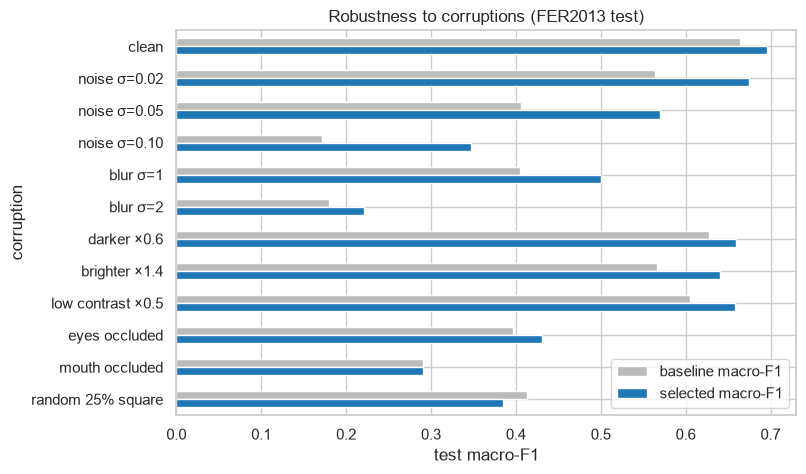

In [22]:
def gaussian_blur(x, sigma):
    k = int(2 * round(3 * sigma) + 1)
    ax_ = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    g = torch.exp(-ax_ ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), g.view(1, 1, 1, k))
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), g.view(1, 1, k, 1))

def make_noise(sigma):
    def f(x):
        g = torch.Generator(device="cpu").manual_seed(123)
        return (x + sigma * torch.randn(x.shape, generator=g).to(x.device)).clamp(0, 1)
    return f

def band(y0, y1):
    def f(x):
        x = x.clone(); H = x.shape[-1]; x[:, :, int(y0 * H):int(y1 * H), :] = 0; return x
    return f

def random_square(frac):
    def f(x):
        x = x.clone(); H = x.shape[-1]; s = int(H * math.sqrt(frac))
        g = torch.Generator().manual_seed(7)
        for i in range(len(x)):
            y0, x0 = (int(v) for v in torch.randint(0, H - s + 1, (2,), generator=g))
            x[i, :, y0:y0 + s, x0:x0 + s] = 0
        return x
    return f

PERTURB = {"clean": None, "noise σ=0.02": make_noise(0.02), "noise σ=0.05": make_noise(0.05),
           "noise σ=0.10": make_noise(0.10), "blur σ=1": lambda x: gaussian_blur(x, 1.0),
           "blur σ=2": lambda x: gaussian_blur(x, 2.0), "darker ×0.6": lambda x: (x * 0.6).clamp(0, 1),
           "brighter ×1.4": lambda x: (x * 1.4).clamp(0, 1),
           "low contrast ×0.5": lambda x: ((x - x.mean((2, 3), keepdim=True)) * 0.5 + x.mean((2, 3), keepdim=True)).clamp(0, 1),
           "eyes occluded": band(0.20, 0.45), "mouth occluded": band(0.62, 0.90), "random 25% square": random_square(0.25)}

ROBUST = None
if C.RUN_STAGES["robustness"]:
    rows = []
    for name_, fn in PERTURB.items():
        r = {"corruption": name_}
        if BASELINE_ID:
            r["baseline macro-F1"] = compute_metrics(Y_TEST, predict_split(BASELINE_ID, FER_TEST, "test", tta=USE_TTA, perturb=fn))["macro_f1"]
        r["selected macro-F1"] = compute_metrics(Y_TEST, sel_predict(FER_TEST, "test", perturb=fn))["macro_f1"]
        rows.append(r)
    ROBUST = pd.DataFrame(rows).set_index("corruption")
    display(ROBUST.round(4))
    ROBUST.to_csv(OUT / "tables" / "robustness.csv")
    ax = ROBUST.plot.barh(figsize=(8, 5), color=["#bbbbbb", "#1f77b4"][-ROBUST.shape[1]:])
    ax.invert_yaxis(); ax.set_xlabel("test macro-F1"); ax.set_title("Robustness to corruptions (FER2013 test)")
    save_fig(ax.figure, "stageK_robustness")

## Stage L — Efficiency and export
Latency is measured for **one image end to end inside PyTorch** (uint8 48 px → resize → normalise → forward), batch 1,
after warm-up, on CPU and (if present) GPU. Parameters and checkpoint size are reported separately. The selected
deployable checkpoint is exported to ONNX (input: 1×1×H×W grayscale in [0, 1]) and checked against PyTorch.

,exp_id,model,input px,params (M),checkpoint (MB),CPU ms (median),CPU ms (p95),CPU images/s,val macro-F1
9,D_custom_cnn_noattn_s0,custom_cnn_noattn,48,1.241,4.996,3.423,25.935,292.137,0.598
1,D_vit_small_patch16_224_s0,vit_small_patch16_224,112,21.612,86.500,10.597,55.037,94.370,0.660
8,D_custom_attn_cnn_s0,custom_attn_cnn,48,1.263,5.090,11.471,27.596,87.180,0.559
2,D_deit_tiny_patch16_224_s0,deit_tiny_patch16_224,112,5.498,22.042,13.503,45.363,74.057,0.649
6,D_hybrid_cnn_transformer_s0,hybrid_cnn_transformer,112,3.918,15.728,14.881,32.036,67.201,0.612
7,D_mobilenetv3_large_100_s0,mobilenetv3_large_100,112,4.211,17.039,24.758,63.951,40.390,0.650
4,D_convnext_tiny_s0,convnext_tiny,112,27.826,111.363,25.946,59.970,38.542,0.652
5,D_efficientnet_b0_s0,efficientnet_b0,112,4.017,16.344,27.069,71.491,36.942,0.653
3,D_resnet50_s0,resnet50,112,23.522,94.395,36.942,95.937,27.070,0.648
0,A1_report_resnet50,tv_resnet50,224,23.522,94.391,55.311,119.331,18.080,0.647


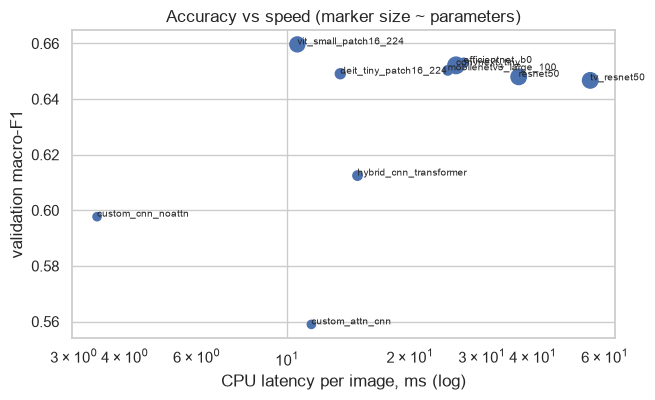

ONNX exported: C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\New Notebook\Facial Emotion Research\outputs\export\vit_small_patch16_224_fer.onnx (86.6 MB)
ONNX Runtime check: max |logit difference| vs PyTorch = 1.43e-06


In [23]:
@torch.no_grad()
def latency_ms(model, size, device, runs=C.LATENCY_RUNS, warm=C.LATENCY_WARMUP):
    model = copy.deepcopy(model).to(device).eval()
    raw = torch.from_numpy(IMAGES[FER_TEST[:1]]).to(device)
    def once():
        x = raw.float().div(255).unsqueeze(1)
        x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False) if size != S else x
        return model(x)
    for _ in range(warm):
        once()
    ts = []
    for _ in range(runs):
        if device.type == "cuda":
            torch.cuda.synchronize()
        t = time.perf_counter(); once()
        if device.type == "cuda":
            torch.cuda.synchronize()
        ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts)), float(np.percentile(ts, 95))

eff_ids = list(dict.fromkeys(([BASELINE_ID] if BASELINE_ID else []) + SEL_MEMBERS +
                             [r["exp_id"] for r in ARCH.values() if r]))
eff = []
for e in eff_ids:
    m = load_model(e)
    size = m.fixed_size or RUNS[e]["recipe"]["img_size"]
    cpu_med, cpu_p95 = latency_ms(m, size, torch.device("cpu"))
    row = {"exp_id": e, "model": RUNS[e]["model"], "input px": size, "params (M)": RUNS[e]["params_m"],
           "checkpoint (MB)": (OUT / "runs" / RUNS[e]["exp_id"] / "best.pt").stat().st_size / 1e6,
           "CPU ms (median)": cpu_med, "CPU ms (p95)": cpu_p95, "CPU images/s": 1000 / cpu_med,
           "val macro-F1": RUNS[e]["val"]["macro_f1"]}
    if DEVICE.type == "cuda":
        row["GPU ms (median)"], _ = latency_ms(m, size, DEVICE)
    eff.append(row)
    del m
EFF = pd.DataFrame(eff).sort_values("CPU ms (median)")
display(EFF.round(3))
EFF.to_csv(OUT / "tables" / "efficiency.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(EFF["CPU ms (median)"], EFF["val macro-F1"], s=30 + 4 * EFF["params (M)"])
for _, r_ in EFF.iterrows():
    ax.annotate(r_["model"], (r_["CPU ms (median)"], r_["val macro-F1"]), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("CPU latency per image, ms (log)"); ax.set_ylabel("validation macro-F1")
ax.set_title("Accuracy vs speed (marker size ~ parameters)")
save_fig(fig, "stageL_accuracy_vs_latency")

ONNX_PATH = None
if C.RUN_STAGES["export_onnx"]:
    m = load_model(SELECTION["deployable"]).cpu().eval()
    size = m.fixed_size or RUNS[SELECTION["deployable"]]["recipe"]["img_size"]
    dummy = torch.rand(1, 1, size, size)
    ONNX_PATH = OUT / "export" / f"{RUNS[SELECTION['deployable']]['model']}_fer.onnx"
    warnings.filterwarnings("ignore", category=DeprecationWarning)
    warnings.filterwarnings("ignore", category=torch.jit.TracerWarning)
    try:
        try:
            torch.onnx.export(m, dummy, str(ONNX_PATH), input_names=["gray_0to1"], output_names=["logits"],
                              dynamic_axes={"gray_0to1": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17,
                              dynamo=False)
        except TypeError:
            torch.onnx.export(m, dummy, str(ONNX_PATH), input_names=["gray_0to1"], output_names=["logits"],
                              dynamic_axes={"gray_0to1": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
        print(f"ONNX exported: {ONNX_PATH} ({ONNX_PATH.stat().st_size / 1e6:.1f} MB)")
        try:
            import onnxruntime as ort
            sess = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
            diff = np.abs(sess.run(None, {"gray_0to1": dummy.numpy()})[0] - m(dummy).detach().numpy()).max()
            print(f"ONNX Runtime check: max |logit difference| vs PyTorch = {diff:.2e}")
        except ImportError:
            print("onnxruntime not installed — export not verified (pip install onnxruntime).")
    except Exception as e:
        ONNX_PATH = None
        print(f"ONNX export skipped: {type(e).__name__}: {str(e)[:200]} (pip install onnx onnxscript)")
    meta_card = {"classes": CLASSES, "input": f"1x1x{size}x{size} grayscale face crop scaled to [0,1]",
                 "face_crop": "square face box + margin, see FaceCropper", "selection": SELECTION}
    _ = (OUT / "export" / "model_card.json").write_text(json.dumps(meta_card, indent=1))
    del m

## M. Results summary
Everything below is generated from the measurements above; nothing is typed in by hand.

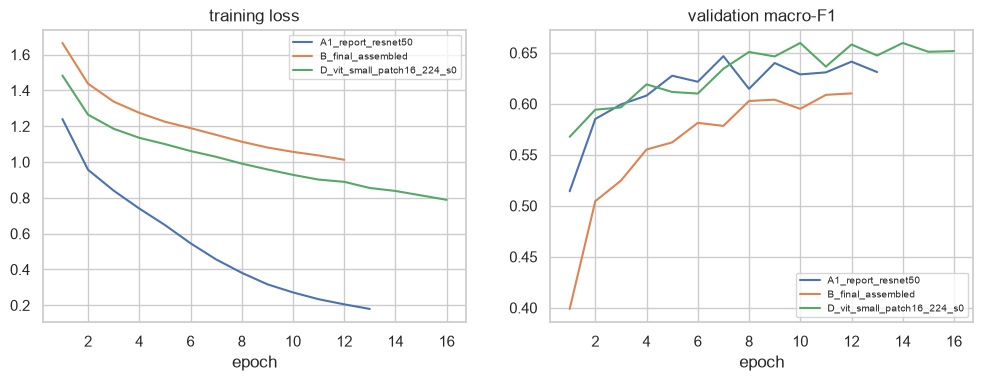

27 training runs; 1 flagged as collapsed; 0 requested pretrained weights that were not available.


UnicodeEncodeError: 'charmap' codec can't encode character '\u2192' in position 367: character maps to <undefined>

In [24]:
# learning curves of the key runs
key_runs = [k for k in [BASELINE_ID, "B_final_assembled" if "B_final_assembled" in RUNS else "B1_proposed",
                        SELECTION["deployable"]] if k and k in RUNS]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k in dict.fromkeys(key_runs):
    h = pd.read_csv(OUT / "runs" / RUNS[k]["exp_id"] / "history.csv")
    axes[0].plot(h.epoch, h.train_loss, label=k); axes[1].plot(h.epoch, h.val_macro_f1, label=k)
axes[0].set_title("training loss"); axes[1].set_title("validation macro-F1")
for a in axes:
    a.set_xlabel("epoch"); a.legend(fontsize=7)
save_fig(fig, "summary_learning_curves")

ALL_RUNS = runs_table()
ALL_RUNS.to_csv(OUT / "tables" / "all_runs.csv", index=False)
print(f"{len(ALL_RUNS)} training runs; {int(ALL_RUNS['collapsed'].sum())} flagged as collapsed; "
      f"{int((~ALL_RUNS['pretrained'] & ALL_RUNS['regime'].ne('scratch') & ~ALL_RUNS['model'].str.startswith('custom')).sum())} "
      "requested pretrained weights that were not available.")

lines = [f"### Measured outcome (profile `{C.RUN_PROFILE}`, FER2013 {FER_PROTOCOL} protocol, "
         f"test n = {len(FER_TEST):,})", ""]
lines.append(f"* **Selected model** (by mean validation macro-F1): `{SELECTION['candidate']}` — "
             f"val macro-F1 {SELECTION['val_macro_f1_mean']:.4f} ± {SELECTION['val_macro_f1_std']:.4f}.")
sel_row = TEST_TABLE[TEST_TABLE.selected].iloc[0]
if SELECTION["type"] == "ensemble":
    lines.append(f"* **Test (selected ensemble of {len(SEL_MEMBERS)} models):** accuracy {SEL_TEST['acc']:.4f}, "
                 f"macro-F1 {SEL_TEST['macro_f1']:.4f}.")
else:
    lines.append(f"* **Test (selected):** accuracy {SEL_TEST['acc']:.4f}, macro-F1 {SEL_TEST['macro_f1']:.4f} "
                 f"(deployable checkpoint = best-validation seed); mean over {int(sel_row['n_seeds'])} seed(s): "
                 f"macro-F1 {sel_row['test_macro_f1_mean']:.4f} ± {sel_row['test_macro_f1_std']:.4f}.")
if COMPARISON:
    sig = "statistically significant" if COMPARISON["mcnemar_p"] < 0.05 and COMPARISON["ci95_delta_macro_f1"][0] > 0 else "not statistically significant"
    lines.append(f"* **Versus the reproduced report baseline (A1):** accuracy {COMPARISON['baseline_acc']:.4f} → "
                 f"{COMPARISON['selected_acc']:.4f} ({COMPARISON['delta_acc']:+.4f}, 95 % CI "
                 f"[{COMPARISON['ci95_delta_acc'][0]:+.4f}, {COMPARISON['ci95_delta_acc'][1]:+.4f}]); macro-F1 "
                 f"{COMPARISON['baseline_macro_f1']:.4f} → {COMPARISON['selected_macro_f1']:.4f} "
                 f"({COMPARISON['delta_macro_f1']:+.4f}, CI [{COMPARISON['ci95_delta_macro_f1'][0]:+.4f}, "
                 f"{COMPARISON['ci95_delta_macro_f1'][1]:+.4f}]); McNemar p = {COMPARISON['mcnemar_p']:.3g} → **{sig}**.")
if (OUT / "tables" / "stageB_decisions.csv").exists():
    dd = pd.read_csv(OUT / "tables" / "stageB_decisions.csv")
    kept = dd[dd.decision.astype(str).str.startswith("keep")]["component"].tolist()
    dropped = dd[dd.decision.astype(str).str.startswith("drop")]["component"].tolist()
    lines.append(f"* **Recipe components that helped on validation:** {', '.join(kept) or 'none'}; "
                 f"**dropped (no gain > {TOL}):** {', '.join(dropped) or 'none'}; imbalance strategy: "
                 f"`{FINAL_RECIPE.imbalance}`; resolution {FINAL_RECIPE.img_size} px; flip-TTA {'on' if USE_TTA else 'off'}.")
if REG and all(REG.get(k) for k in ["scratch", "linear_probe", "finetune"]):
    lines.append("* **Training regime (val macro-F1):** " + ", ".join(f"{k} {vf1(v):.4f}" for k, v in REG.items()) + ".")
if ARCH and any(ARCH.values()):
    top = sorted([r for r in ARCH.values() if r], key=vf1, reverse=True)
    lines.append("* **Architectures (val macro-F1, seed 0):** " + ", ".join(f"{r['model']} {vf1(r):.4f}" for r in top) + ".")
    if ARCH.get("custom_attn_cnn") and ARCH.get("custom_cnn_noattn"):
        lines.append(f"* **CBAM attention ablation:** {vf1(ARCH['custom_attn_cnn']) - vf1(ARCH['custom_cnn_noattn']):+.4f} val macro-F1.")
if LABELS.get("ferplus_soft"):
    lines.append(f"* **FER+ soft labels:** {vf1(LABELS['ferplus_soft']) - vf1(LABELS['fer2013']):+.4f} val macro-F1 "
                 "vs original labels (same architecture).")
if CROSS is not None:
    c = "frame macro-F1 (closed)"
    for name in EXTERNAL:
        sub = CROSS.loc[name] if name in CROSS.index.get_level_values(0) else None
        if sub is not None:
            lines.append(f"* **{name}:** " + "; ".join(f"{t}: {v:.4f}" for t, v in sub[c].items()) + f" ({c}).")
if ROBUST is not None:
    worst = ROBUST["selected macro-F1"].drop("clean").idxmin()
    lines.append(f"* **Robustness:** clean macro-F1 {ROBUST.loc['clean', 'selected macro-F1']:.4f}; largest drop under "
                 f"*{worst}* ({ROBUST.loc[worst, 'selected macro-F1']:.4f}).")
sel_eff = EFF[EFF.exp_id.isin(SEL_MEMBERS)]
if len(sel_eff):
    lines.append(f"* **Selected model speed (model only, batch 1):** {sel_eff['CPU ms (median)'].sum():.1f} ms per image on "
                 f"this CPU, {sel_eff['params (M)'].sum():.1f} M parameters"
                 f"{' in total for the ensemble' if len(sel_eff) > 1 else ''}.")
if C.RUN_PROFILE == "smoke":
    lines.append("* ⚠ **Smoke profile:** tiny subsets and 1–2 epochs. These numbers only prove the pipeline runs; "
                 "they say nothing about model quality.")
SUMMARY_MD = "\n".join(lines)
_ = (OUT / "tables" / "summary.md").write_text(SUMMARY_MD)
display(Markdown(SUMMARY_MD))

## Limitations and recommended next steps

**Limitations of this study**
* **Labels.** FER2013 labels are noisy (human accuracy is reported at about 65 ± 5 %); the test labels themselves
  limit how far any model can be measured to improve. The FER+ comparison in § E quantifies this.
* **Single-seed ablations.** Stage B and the seed-0 architecture sweep use one seed; deltas below the tolerance are
  treated as noise, and only finalists get several seeds. Components may interact; B_final checks the assembled recipe once.
* **No subject IDs in FER2013.** Leakage is controlled with exact and near-duplicate checks, but identities can still
  repeat across splits. CK+, RAVDESS and CREMA-D splits are fully subject-independent.
* **Acted vs spontaneous data.** CK+, RAVDESS and CREMA-D are posed recordings in studio conditions; cross-dataset scores
  measure transfer between collection protocols, not real-world robot conditions.
* **Face detection.** OpenCV Haar (or YuNet) crops; the fallback rate is reported per dataset. A landmark-based aligner
  would reduce pose variance.
* **Video datasets used as images.** Frames are classified independently and averaged; no temporal model and no audio is
  used. RAVDESS and CREMA-D are audio-visual datasets, so this underuses them.
* **Latency** is measured inside PyTorch on the machine running this notebook, not on the robot's hardware, and excludes
  camera capture and face detection.

**Recommended next steps**
1. Run the `full` profile on a GPU and report the multi-seed mean ± std from § H as the headline result.
2. If FER+ soft labels helped, also report results on FER+ test labels, the cleaner benchmark used by recent papers.
3. Try face-domain pretraining (`HSEMOTION_WEIGHTS`) and FER-specific architectures (POSTER++, DDAMFN) under this exact protocol.
4. Distil the ensemble (if it won) into the fastest Stage-D model for the robot; quantise the ONNX export to INT8 and
   re-measure accuracy and latency on the target board.
5. For RAVDESS/CREMA-D, add a temporal model over frame embeddings and an audio branch (late fusion first).
6. Treat outputs as predictions of dataset-defined expression labels, not measurements of a person's inner state;
   test fairness across age, gender and skin tone before any deployment.

In [ ]:
print("Saved outputs:")
for sub in ["tables", "plots", "export"]:
    files = sorted(p.name for p in (OUT / sub).iterdir())
    print(f"  {sub}/ ({len(files)} files): {', '.join(files[:12])}{' ...' if len(files) > 12 else ''}")
print(f"  runs/ ({len(list((OUT / 'runs').iterdir()))} run folders with result.json, history.csv, best.pt, val_probs.npy)")
print("Selection:", OUT / "selection.json")